<p class="lead">Every number a laboratory publishes is an estimate: a quantity computed from the handful of molecules, patients or trajectories that happened to be measured, standing in for a quantity about a population that was not measured. This unit builds the machinery that turns a number into a <em>claim with an interval</em> — the only form in which a number is publishable. We rebuild probability from simulation rather than from formula tables: a distribution is something we sample from and plot, a standard error is something we measure by repeating an experiment ten thousand times in silico, and a confidence interval is something whose coverage we check. Three real datasets anchor the whole unit: the ROCK1 bioactivity table the laboratory curates, the replica molecular-dynamics trajectories of the Trp-cage miniprotein, and a gingival-tissue expression matrix. The unit closes with the two facts that most often invalidate an interval in our field — the <strong>experimental noise floor</strong> of a public bioactivity dataset, and the <strong>autocorrelation</strong> of a simulation time series, which makes 500 frames behave like four independent measurements.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad reconstruye la probabilidad y la estimación mediante simulación, no mediante tablas de fórmulas. Se repasan variables aleatorias, esperanza y varianza; se reconocen las distribuciones normal, log-normal, binomial, de Poisson y t en datos reales del laboratorio; se demuestran por experimento la ley de los grandes números y el teorema central del límite; se explica por qué las potencias se analizan como pActivity (−log10 de la concentración molar) mostrando que el promedio de los IC50 y el promedio de los pIC50 responden a preguntas distintas; se calculan errores estándar e intervalos de confianza paramétricos y bootstrap (percentil y BCa); se introducen resúmenes robustos (mediana, MAD, media recortada) y las correlaciones de Pearson, Spearman y Kendall con sus intervalos. Finalmente se estima el piso de ruido experimental del conjunto ROCK1 y se muestra que en una trayectoria de dinámica molecular 500 fotogramas equivalen a unas pocas muestras independientes.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Reason with random variables, expectation and variance, and recognise the normal, log-normal, binomial, Poisson and t distributions in laboratory data.</li>
<li>Explain the law of large numbers and the central limit theorem by simulation, and say what each one does and does not promise.</li>
<li>Explain why half-maximal inhibitory concentrations are analysed as pIC50, and show that the mean of IC50 and the mean of pIC50 answer different questions.</li>
<li>Distinguish population, sample, estimator and estimate, and separate sampling variability from measurement error.</li>
<li>Compute and interpret standard errors and confidence intervals analytically and with the percentile and BCa bootstrap, and report uncertainty with every estimate.</li>
<li>Use robust summaries (median, MAD, trimmed mean) and know their breakdown points.</li>
<li>Compute Pearson, Spearman and Kendall correlations with confidence intervals and know which to report.</li>
<li>Estimate the experimental noise floor of a bioactivity dataset and the effective sample size of a correlated time series.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it linearly once, running every cell and reading the output before the next paragraph; then go back and change one thing at a time — the sample size, the seed, the estimator — and watch the intervals move. Everything runs on the default scientific Python stack: NumPy<sup class="c"><a href="#r1">[1]</a></sup>, pandas<sup class="c"><a href="#r2">[2]</a></sup>, SciPy<sup class="c"><a href="#r3">[3]</a></sup> and Matplotlib<sup class="c"><a href="#r4">[4]</a></sup>, all of them pre-installed in Google Colab, so no installation line is needed for this unit. Boxes marked <em>Domain context</em> define the chemistry, biology and simulation vocabulary as it appears; boxes marked <em>Exercise</em> ask you to modify the cell above them. This unit follows Unit 5 (exploratory analysis) and Unit 6 (curation) and is the foundation of Unit 8 (hypothesis testing), Unit 9 (linear models) and Unit 12 (confidence intervals on model metrics).</p></div>

In [1]:
# Setup. Everything used here is pre-installed in Google Colab; no !pip install is needed.
from pathlib import Path
import urllib.request
import numpy as np, pandas as pd, scipy, matplotlib, matplotlib.pyplot as plt
from scipy import stats
np.random.seed(0)
rng = np.random.default_rng(0)          # one generator, one seed, for the whole notebook
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | matplotlib 3.11.0


In [2]:
# The two tables this unit works on.
rock = load_data("rock1_chembl_curated.csv")       # 1 row per standardised compound
md_obs = load_data("md_trpcage_observables.csv")   # 6 trajectories x 500 frames
exact = rock.loc[~rock["censored"]].reset_index(drop=True)   # compounds with at least one '=' measurement
print("ROCK1 compounds:", len(rock), "| with an exact measurement:", len(exact),
      "| censored only:", int(rock['censored'].sum()))
print("pActivity (exact subset): mean %.3f, sd %.3f, median %.3f, min %.2f, max %.2f"
      % (exact.pActivity.mean(), exact.pActivity.std(), exact.pActivity.median(),
         exact.pActivity.min(), exact.pActivity.max()))
print("MD table:", md_obs.shape, "| conditions:", sorted(md_obs.condition.unique()),
      "| replicas:", sorted(md_obs.replica.unique()), "| frames per run:",
      int(md_obs.groupby(["condition", "replica"], observed=True).size().iloc[0]))

ROCK1 compounds: 4280 | with an exact measurement: 2764 | censored only: 1516
pActivity (exact subset): mean 6.508, sd 1.109, median 6.435, min 3.57, max 9.82
MD table: (3000, 11) | conditions: ['A', 'B'] | replicas: [np.int64(1), np.int64(2), np.int64(3)] | frames per run: 500


## 1. Population, sample, estimator, estimate

Four words do most of the work in this unit, and confusing them is the commonest source of wrong intervals.

A **population** is the set of all values the question is about. It is almost always hypothetical: *the potency against ROCK1 of every molecule our medicinal chemists could synthesise in this series*, *the conformations the Trp-cage miniprotein visits at 300 K*, *the gene-expression profile of inflamed gingival tissue in the human population*. A **sample** is the finite subset we actually measured — 2,764 compounds, 500 frames, 69 patients. An **estimator** is a *rule* for computing something from a sample: "take the arithmetic mean", "take the median", "take the 20 % trimmed mean". An **estimate** is the *number* that rule returns on our particular sample.

The distinction between estimator and estimate is the whole of inferential statistics. The estimate is one number and has no uncertainty — it is what it is. The estimator is a random variable: run the experiment again and the same rule returns a different number. The spread of those hypothetical repetitions is the **sampling distribution**, its standard deviation is the **standard error**, and a confidence interval is a statement about that spread.

Two different sources of variation get folded into "uncertainty" and they must be separated:

| source | what it is | how we estimate it here |
|---|---|---|
| **sampling variability** | we measured 2,764 of the possible compounds, not all of them | bootstrap, standard error, CLT |
| **measurement error** | the same compound re-assayed gives a different IC50 | replicate spread within a compound (§10) |

A confidence interval for a mean computed from one assay per compound captures the first and ignores the second. Section 10 measures the second directly, and the comparison is sobering.

<div class="box bridge"><h4>Domain context — what a potency measurement is</h4>
<p>A <strong>target</strong> is the protein a drug is meant to act on; ours is <strong>ROCK1</strong> (Rho-associated protein kinase 1), a human enzyme that transfers phosphate groups onto other proteins and whose inhibitors are studied for glaucoma and fibrosis. An <strong>assay</strong> is a laboratory experiment that measures how strongly a molecule interferes with the target. Its usual read-out is the <strong>IC50</strong>: the concentration of compound at which the target's activity is halved, in moles per litre. Smaller is better — a 1 nM compound is a thousand times more potent than a 1 µM one. Closely related read-outs are <strong>Ki</strong> (an inhibition constant, related to IC50 through the Cheng–Prusoff equation<sup class="c"><a href="#r5">[5]</a></sup>) and <strong>Kd</strong> (a binding dissociation constant). Because these numbers span many orders of magnitude, the field converts them to a logarithmic scale: <strong>pActivity = −log<sub>10</sub>(concentration in M)</strong>, so 1 nM = 10<sup>−9</sup> M becomes pActivity 9 and 1 µM becomes 6. Our table, curated from the public ChEMBL database<sup class="c"><a href="#r6">[6]</a></sup>, holds one row per compound with the median pActivity of its measurements. A compound whose measurement is reported only as "IC50 &gt; 10 µM" is <strong>censored</strong>: we know the potency is below a bound but not its value, and such rows are excluded from this unit's estimates (they are flagged by the column <code>censored</code>).</p></div>

The first experiment makes the distinction concrete. We treat the 2,764 measured compounds as if they were the whole population — which they are not, but it lets us *see* the sampling distribution — and draw repeated samples of 25 compounds.

population mean 6.508, population median 6.435
estimator SD: mean 0.2248 | median 0.2766  (ratio 1.23)
sigma/sqrt(n) prediction for the mean: 0.2217


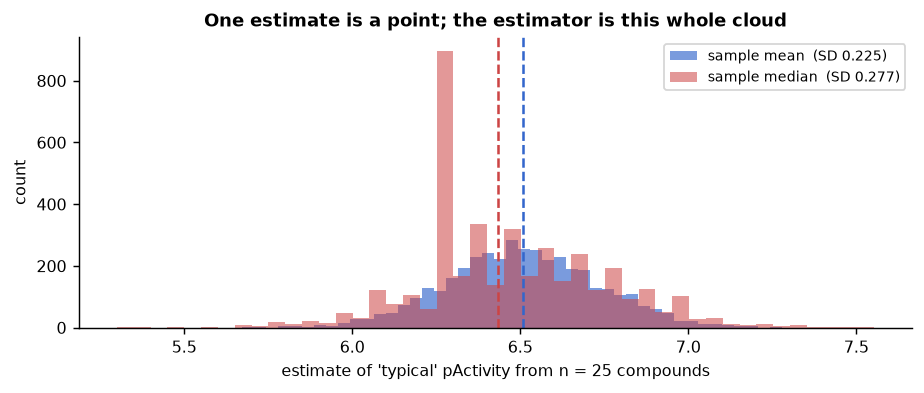

In [3]:
# Sampling distribution of two estimators of 'typical potency', seen directly.
population = exact["pActivity"].to_numpy()
truth_mean, truth_med = population.mean(), np.median(population)
n_draw, n_rep = 25, 4000
samples = rng.choice(population, size=(n_rep, n_draw), replace=True)
means = samples.mean(axis=1)
medians = np.median(samples, axis=1)

fig, ax = plt.subplots(figsize=(7.2, 3.1))
ax.hist(means, bins=45, alpha=0.65, label=f"sample mean  (SD {means.std(ddof=1):.3f})", color="#36c")
ax.hist(medians, bins=45, alpha=0.55, label=f"sample median  (SD {medians.std(ddof=1):.3f})", color="#c44")
ax.axvline(truth_mean, color="#36c", lw=1.4, ls="--")
ax.axvline(truth_med, color="#c44", lw=1.4, ls="--")
ax.set_xlabel("estimate of 'typical' pActivity from n = 25 compounds"); ax.set_ylabel("count")
ax.set_title("One estimate is a point; the estimator is this whole cloud"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("population mean %.3f, population median %.3f" % (truth_mean, truth_med))
print("estimator SD: mean %.4f | median %.4f  (ratio %.2f)"
      % (means.std(ddof=1), medians.std(ddof=1), medians.std(ddof=1) / means.std(ddof=1)))
print("sigma/sqrt(n) prediction for the mean: %.4f" % (population.std(ddof=1) / np.sqrt(n_draw)))

<p class="caption"><b>Figure 1.</b> Sampling distributions of two estimators of "typical potency", obtained by drawing 4,000 samples of 25 compounds from the 2,764 measured ROCK1 compounds. Both clouds are centred near their respective population values (about 6.51 for the mean, 6.44 for the median), but they are clouds: a single study of 25 compounds could easily report 6.2 or 6.8. The standard deviation of the mean cloud, about 0.22 log units, is reproduced by the formula σ/√n printed below the figure. The median cloud is about 20 % wider, the price of the robustness bought in §9.</p>

We never see this cloud in a real study, because we get one sample. The rest of the unit reconstructs its width from that single sample — analytically (§7), by resampling (§8), or by knowing the distribution the data came from (§3).

## 2. Random variables, expectation and variance by simulation

A **random variable** is a number produced by a process whose outcome is not determined in advance: the potency of the next compound the chemists make, the number of hydrogen bonds in the next simulation frame, whether a screening hit turns out to be active. Its **expectation** $\mathbb{E}[X]$ is the long-run average of that number, and its **variance** $\operatorname{Var}(X)=\mathbb{E}[(X-\mathbb{E}[X])^2]$ is the long-run average squared deviation from it; the **standard deviation** $\sigma=\sqrt{\operatorname{Var}(X)}$ brings it back to the units of $X$.

Three properties carry nearly all the algebra you need, and all three are worth checking by simulation rather than memorising:

$$\mathbb{E}[aX+b]=a\,\mathbb{E}[X]+b,\qquad \operatorname{Var}(aX+b)=a^{2}\operatorname{Var}(X),\qquad \operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)\ \text{if $X,Y$ independent.}$$

The third is the one that fails most often in our data, and the failure is the subject of §11: frames of a trajectory are not independent, so the variance of their sum is larger than the sum of their variances, and every uncertainty computed as if they were independent is too small.

The **law of large numbers** (LLN) says that the sample mean of independent draws converges to the expectation as $n$ grows. It says nothing about how fast, and nothing about the shape of the error — those are the central limit theorem's business (§5).

after    100 compounds: running hit rate 0.0600  (theoretical SE 0.0271)
after   1000 compounds: running hit rate 0.0740  (theoretical SE 0.0086)
after  10000 compounds: running hit rate 0.0774  (theoretical SE 0.0027)
after  20000 compounds: running hit rate 0.0784  (theoretical SE 0.0019)


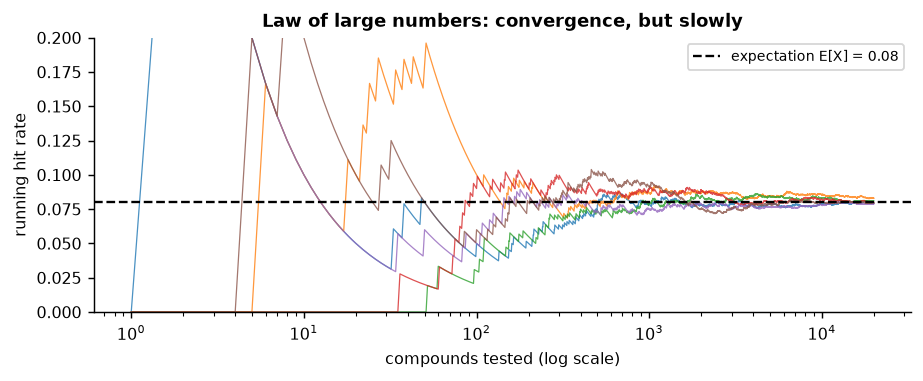

In [4]:
# The law of large numbers, and what it does not promise.
p_hit = 0.08                                  # an 8 % hit rate in a screening campaign
draws = rng.random(20000) < p_hit             # Bernoulli(0.08): one screen, 20000 compounds tested
running = np.cumsum(draws) / np.arange(1, len(draws) + 1)

fig, ax = plt.subplots(figsize=(7.2, 3.0))
for trial in range(6):                        # six independent campaigns
    d = rng.random(20000) < p_hit
    ax.plot(np.arange(1, 20001), np.cumsum(d) / np.arange(1, 20001), lw=0.7, alpha=0.8)
ax.axhline(p_hit, color="k", lw=1.3, ls="--", label="expectation E[X] = 0.08")
ax.set_xscale("log"); ax.set_xlabel("compounds tested (log scale)"); ax.set_ylabel("running hit rate")
ax.set_ylim(0, 0.2); ax.set_title("Law of large numbers: convergence, but slowly"); ax.legend(fontsize=7.5)
fig.tight_layout()
for n in (100, 1000, 10000, 20000):
    print("after %6d compounds: running hit rate %.4f  (theoretical SE %.4f)"
          % (n, running[n - 1], np.sqrt(p_hit * (1 - p_hit) / n)))

<p class="caption"><b>Figure 2.</b> Six simulated screening campaigns with a true hit rate of 8 %. Each line is the running estimate after the first <i>n</i> compounds. At <i>n</i> = 100 the campaigns disagree by several percentage points; only after about 10,000 compounds do all six lines sit within roughly one percentage point of the truth. The printed standard errors show why: the uncertainty falls as 1/√n, so reducing it tenfold costs a hundredfold more experiments.</p>

Note what the law of large numbers does *not* say. It does not say that an unlucky campaign is "due" a hit — the compounds are independent — and it assumes the draws come from the same distribution: if the chemists change the library halfway through, the running average converges to nothing in particular.

## 3. The distributions you will actually meet

Five distributions cover the overwhelming majority of laboratory data. The skill to acquire is recognising which one a column plausibly came from, because that choice determines whether a mean is meaningful, which test applies (Unit 8) and which transform to use.

<div class="box key"><h4>The five, and where they come from</h4>
<ul>
<li><b>Normal</b> — a quantity built by adding many small independent contributions. Physical measurements after transformation, instrument noise, and (by the CLT) averages of almost anything.</li>
<li><b>Log-normal</b> — a quantity built by <i>multiplying</i> many small independent factors, and therefore positive and right-skewed. Concentrations, IC50 values, reaction rates, gene-expression intensities before the log<sub>2</sub>.</li>
<li><b>Binomial</b> — the count of successes in <i>n</i> independent yes/no trials with constant probability. Hits in a screen, actives above a potency threshold, patients responding to a treatment.</li>
<li><b>Poisson</b> — the count of events in a fixed window when events are rare and independent. Hydrogen bonds in a frame, contacts within a cutoff, reads mapped to a gene, mutations per kilobase.</li>
<li><b>Student's <i>t</i></b> — not a model of data but the sampling distribution of a standardised mean when the variance is estimated from the same small sample<sup class="c"><a href="#r7">[7]</a></sup>. It is why small-sample intervals are wider than 1.96 standard errors.</li>
</ul></div>

The next cell puts four real columns next to the textbook density that claims to describe them.

IC50 (nM): mean 4176, median 367, max 269774
log10 IC50: skew -0.06 | raw IC50: skew 7.47
n_hbonds: mean 8.699, variance 2.084 -> index of dispersion 0.24


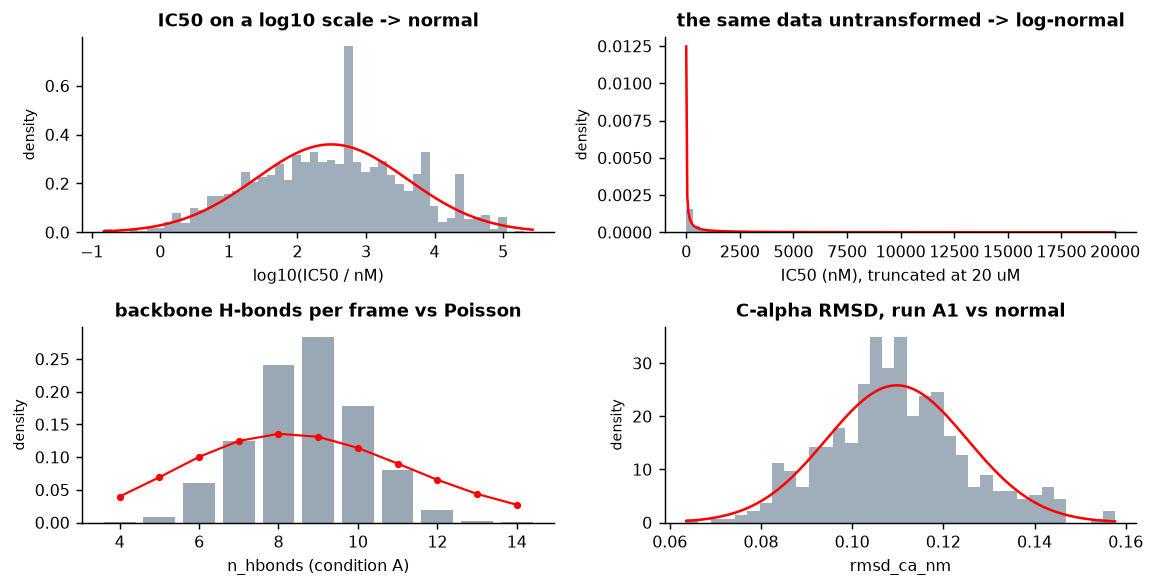

In [5]:
# Four real columns against the distribution that is supposed to describe them.
ic50_nM = 10 ** (9 - exact["pActivity"].to_numpy())          # back-convert pActivity to nM
hb = md_obs.loc[md_obs.condition == "A", "n_hbonds"].to_numpy()
rmsd_a1 = md_obs.query("condition == 'A' and replica == 1")["rmsd_ca_nm"].to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(9.0, 4.6))
ax = axes[0, 0]
ax.hist(np.log10(ic50_nM), bins=50, density=True, color="#89a", alpha=0.8)
xs = np.linspace(np.log10(ic50_nM).min(), np.log10(ic50_nM).max(), 200)
ax.plot(xs, stats.norm(np.log10(ic50_nM).mean(), np.log10(ic50_nM).std()).pdf(xs), "r-", lw=1.4)
ax.set_title("IC50 on a log10 scale -> normal"); ax.set_xlabel("log10(IC50 / nM)")
ax = axes[0, 1]
ax.hist(ic50_nM[ic50_nM < 20000], bins=60, density=True, color="#89a", alpha=0.8)
xs = np.linspace(1, 20000, 400)
shape, loc, scale = stats.lognorm.fit(ic50_nM, floc=0)
ax.plot(xs, stats.lognorm(shape, loc, scale).pdf(xs), "r-", lw=1.4)
ax.set_title("the same data untransformed -> log-normal"); ax.set_xlabel("IC50 (nM), truncated at 20 uM")
ax = axes[1, 0]
vals, counts = np.unique(hb, return_counts=True)
ax.bar(vals, counts / counts.sum(), color="#89a", alpha=0.85)
ax.plot(vals, stats.poisson(hb.mean()).pmf(vals), "ro-", ms=3, lw=1.2)
ax.set_title("backbone H-bonds per frame vs Poisson"); ax.set_xlabel("n_hbonds (condition A)")
ax = axes[1, 1]
ax.hist(rmsd_a1, bins=35, density=True, color="#89a", alpha=0.8)
xs = np.linspace(rmsd_a1.min(), rmsd_a1.max(), 200)
ax.plot(xs, stats.norm(rmsd_a1.mean(), rmsd_a1.std()).pdf(xs), "r-", lw=1.4)
ax.set_title("C-alpha RMSD, run A1 vs normal"); ax.set_xlabel("rmsd_ca_nm")
for a in axes.ravel():
    a.set_ylabel("density", fontsize=8)
fig.tight_layout()
print("IC50 (nM): mean %.0f, median %.0f, max %.0f" % (ic50_nM.mean(), np.median(ic50_nM), ic50_nM.max()))
print("log10 IC50: skew %.2f | raw IC50: skew %.2f" % (stats.skew(np.log10(ic50_nM)), stats.skew(ic50_nM)))
print("n_hbonds: mean %.3f, variance %.3f -> index of dispersion %.2f" % (hb.mean(), hb.var(ddof=1), hb.var(ddof=1) / hb.mean()))

<p class="caption"><b>Figure 3.</b> Four laboratory columns against the textbook density claimed for them. Top left: potencies on the log<sub>10</sub> scale are close to normal (skew below 0.1 in magnitude). Top right: the same numbers untransformed are violently right-skewed (skew about 7.5, mean around 4,200 nM against a median near 370 nM) and the log-normal density follows them. Bottom left: the per-frame count of backbone hydrogen bonds is a count, but the Poisson density with the same mean is too wide — the data are <i>under</i>-dispersed. Bottom right: the C-alpha RMSD of a single 1 ns run is roughly bell-shaped but that appearance is deceptive, for reasons §11 makes explicit.</p>

The bottom-left panel is the unit's first deliberate failure demonstration. The **index of dispersion**, variance divided by mean, equals 1 for a Poisson variable by construction. The printed value for the hydrogen-bond counts is far below 1, meaning the counts cluster much more tightly around their mean than Poisson allows. The reason is physical: a backbone hydrogen bond in a folded miniprotein is not a rare independent event but a structural feature that persists for hundreds of frames, and the number of candidate bonds is bounded by the geometry of a 20-residue chain. "It is a count, therefore it is Poisson" is wrong twice over.

In [6]:
# Is the H-bond count Poisson? A parametric check against a simulated Poisson of the same mean.
lam = hb.mean()
sim = rng.poisson(lam, size=(2000, len(hb)))
sim_disp = sim.var(axis=1, ddof=1) / sim.mean(axis=1)
obs_disp = hb.var(ddof=1) / hb.mean()
print("observed index of dispersion: %.3f" % obs_disp)
print("Poisson reference: %.3f  (95%% range %.3f - %.3f over 2000 simulated datasets)"
      % (sim_disp.mean(), *np.percentile(sim_disp, [2.5, 97.5])))
print("fraction of Poisson datasets at least as under-dispersed: %.4f" % (sim_disp <= obs_disp).mean())
print("\nsame check on a quantity that IS close to Poisson - the number of frames in which")
print("the cage distance exceeds 0.70 nm, counted in blocks of 50 frames:")
far = (md_obs["dist_W6_P12_nm"].to_numpy() > 0.70).astype(int)
blocks = far[: (len(far) // 50) * 50].reshape(-1, 50).sum(axis=1)
print("block counts: mean %.3f, variance %.3f -> index of dispersion %.2f"
      % (blocks.mean(), blocks.var(ddof=1), blocks.var(ddof=1) / blocks.mean()))

observed index of dispersion: 0.240
Poisson reference: 0.999  (95% range 0.929 - 1.074 over 2000 simulated datasets)
fraction of Poisson datasets at least as under-dispersed: 0.0000

same check on a quantity that IS close to Poisson - the number of frames in which
the cage distance exceeds 0.70 nm, counted in blocks of 50 frames:
block counts: mean 0.500, variance 1.441 -> index of dispersion 2.88


The simulation makes the verdict quantitative: not one of 2,000 genuine Poisson datasets of the same size and mean is as under-dispersed as the observed hydrogen-bond counts, so the Poisson model is rejected without any formal test. The second check shows the opposite failure: counting rare excursions of the cage distance in blocks of 50 frames gives an index of dispersion near 3, because the excursions arrive in bursts rather than independently — over-dispersion, the usual state of RNA-sequencing counts. One dataset, two opposite violations of the same assumption. Compute the index of dispersion before assuming Poisson; if it is far from 1 either way, use the empirical distribution, a negative binomial, or a resampling method.

## 4. Why potencies are analysed as pActivity — a worked example by hand

This is the single most consequential transform in our field, and it is worth tracing on paper before trusting any code. Suppose five laboratories measure the same compound and report IC50 values of **2, 5, 10, 50 and 1,000 nM**. What is "the" potency?

| statistic | computation | value |
|---|---|---|
| arithmetic mean of IC50 | (2 + 5 + 10 + 50 + 1000) / 5 | **213.4 nM** |
| median of IC50 | middle of the sorted list | **10 nM** |
| geometric mean of IC50 | (2 × 5 × 10 × 50 × 1000)<sup>1/5</sup> = (5,000,000)<sup>1/5</sup> | **21.87 nM** |
| pIC50 of each value | 9 − log<sub>10</sub>(IC50 in nM) | 8.699, 8.301, 8.000, 7.301, 6.000 |
| mean pIC50 | (8.699 + 8.301 + 8.000 + 7.301 + 6.000) / 5 | **7.660** |
| back-converted mean pIC50 | 10<sup>9 − 7.660</sup> nM | **21.87 nM** |

Three facts fall out of the table, and all three matter.

1. The arithmetic mean of the IC50 values, 213 nM, is larger than four of the five measurements. It is not a typical potency; it is dominated by the single weak measurement. In a right-skewed distribution the arithmetic mean is a statement about the *total*, not about the *typical*.
2. The mean of the pIC50 values back-converts exactly to the **geometric mean** of the IC50 values. Averaging on a log scale and taking a geometric mean are the same operation. This is the sense in which "the mean of IC50 and the mean of pIC50 answer different questions": the first asks what the average concentration is, the second asks what the average *order of magnitude* — the average free energy of binding — is.
3. The second question is the one chemistry asks. Binding affinity is related to free energy by ΔG = −RT ln K, so a logarithmic potency scale is linear in energy; a ten-fold potency improvement costs roughly the same chemical effort whether it starts at 1 µM or at 10 nM. Errors are also multiplicative — an assay is accurate "to within a factor of two", not "to within 3 nM" — which is exactly the generative mechanism that produces a log-normal distribution<sup class="c"><a href="#r8">[8]</a></sup>.

In [7]:
# The hand-worked example, confirmed; then the same comparison on the whole dataset.
vals = np.array([2.0, 5.0, 10.0, 50.0, 1000.0])          # nM
p = 9 - np.log10(vals)
print("hand example  arithmetic mean %.2f nM | median %.2f nM | geometric mean %.2f nM"
      % (vals.mean(), np.median(vals), stats.gmean(vals)))
print("hand example  pIC50 values:", np.round(p, 3), "-> mean pIC50 %.3f -> %.2f nM"
      % (p.mean(), 10 ** (9 - p.mean())))
assert abs(10 ** (9 - p.mean()) - stats.gmean(vals)) < 1e-9     # the two are the same number

print("\nwhole ROCK1 dataset (%d compounds with exact measurements):" % len(exact))
print("  arithmetic mean of IC50-equivalents : %8.1f nM" % ic50_nM.mean())
print("  median of IC50-equivalents          : %8.1f nM" % np.median(ic50_nM))
print("  geometric mean of IC50-equivalents  : %8.1f nM" % stats.gmean(ic50_nM))
print("  back-converted mean pActivity       : %8.1f nM" % (10 ** (9 - exact.pActivity.mean())))
print("  share of the total IC50 sum contributed by the 1%% weakest compounds: %.1f%%"
      % (100 * np.sort(ic50_nM)[-len(ic50_nM) // 100:].sum() / ic50_nM.sum()))

hand example  arithmetic mean 213.40 nM | median 10.00 nM | geometric mean 21.87 nM
hand example  pIC50 values: [8.699 8.301 8.    7.301 6.   ] -> mean pIC50 7.660 -> 21.87 nM

whole ROCK1 dataset (2764 compounds with exact measurements):
  arithmetic mean of IC50-equivalents :   4175.9 nM
  median of IC50-equivalents          :    367.3 nM
  geometric mean of IC50-equivalents  :    310.8 nM
  back-converted mean pActivity       :    310.8 nM
  share of the total IC50 sum contributed by the 1% weakest compounds: 26.0%


The pattern repeats on 2,764 real compounds: the arithmetic mean of the concentrations is about thirteen times the geometric mean, and the weakest one per cent of the compounds contribute roughly a quarter of the total concentration sum. Reporting "the mean IC50 of our series is 4.2 µM" would describe a series whose typical member is around 370 nM. This is not a subtlety — it is the difference between a publishable summary and a misleading one, and the reason every QSAR target variable in this course is a pActivity.

<div class="box warn"><h4>Common error</h4>
<p>Averaging IC50 values in nanomolar and then taking −log<sub>10</sub> of the average is <em>not</em> the same as averaging pIC50 values, and the difference grows with the spread. The curated table in <code>../data/</code> aggregates replicate measurements with the <em>median of the pActivity values</em>, which is both robust and on the correct scale. When you merge data from two sources yourself, convert to pActivity first, then aggregate.</p></div>

## 5. QQ-plots: deciding whether a transform worked

A histogram tells you whether a distribution looks skewed; a **quantile–quantile plot** tells you *where* and *by how much* it departs from a reference distribution, which is far more actionable. Sort the data, compute for each sorted value the quantile of the reference distribution at the matching cumulative probability, and plot one against the other. If the data follow the reference up to location and scale, the points fall on a straight line; curvature at one end is skew, an S-shape is heavy or light tails.

IC50 (nM)    skew    7.47  excess kurtosis   85.52  Shapiro-Wilk W 0.3420
pActivity    skew    0.06  excess kurtosis   -0.44  Shapiro-Wilk W 0.9933


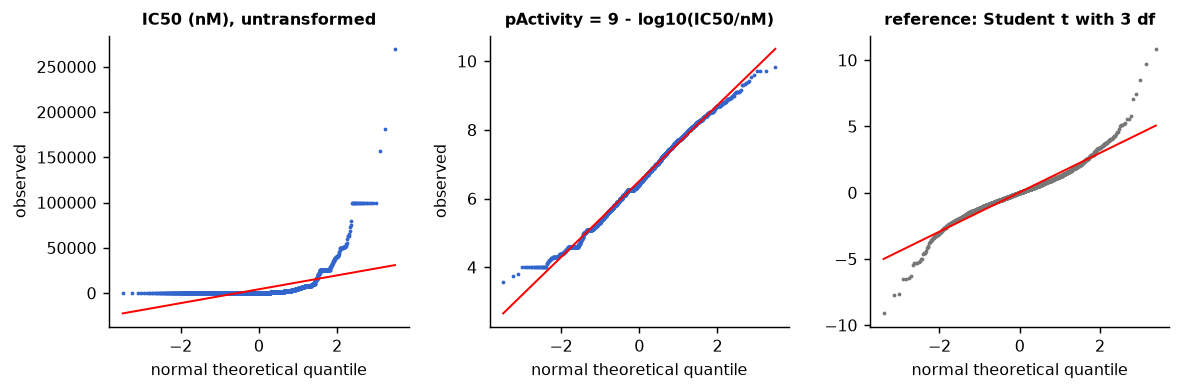

In [8]:
# QQ-plots before and after the log transform, plus a heavy-tailed reference.
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.1))
for ax, data, name in [(axes[0], ic50_nM, "IC50 (nM), untransformed"),
                       (axes[1], exact["pActivity"].to_numpy(), "pActivity = 9 - log10(IC50/nM)")]:
    osm, osr = stats.probplot(data, dist="norm", fit=False)
    ax.plot(osm, osr, ".", ms=2.2, color="#36c")
    lo, hi = osm.min(), osm.max()
    sl, ic = np.polyfit(osm, osr, 1)
    ax.plot([lo, hi], [sl * lo + ic, sl * hi + ic], "r-", lw=1.1)
    ax.set_title(name, fontsize=9); ax.set_xlabel("normal theoretical quantile"); ax.set_ylabel("observed")
t_sample = stats.t(df=3).rvs(2000, random_state=1)
osm, osr = stats.probplot(t_sample, dist="norm", fit=False)
axes[2].plot(osm, osr, ".", ms=2.2, color="#777")
sl, ic = np.polyfit(osm, osr, 1)
axes[2].plot([osm.min(), osm.max()], [sl * osm.min() + ic, sl * osm.max() + ic], "r-", lw=1.1)
axes[2].set_title("reference: Student t with 3 df", fontsize=9); axes[2].set_xlabel("normal theoretical quantile")
fig.tight_layout()
for nm, d in [("IC50 (nM)", ic50_nM), ("pActivity", exact["pActivity"].to_numpy())]:
    print("%-12s skew %7.2f  excess kurtosis %7.2f  Shapiro-Wilk W %.4f"
          % (nm, stats.skew(d), stats.kurtosis(d), stats.shapiro(d[:2000]).statistic))

<p class="caption"><b>Figure 4.</b> Normal QQ-plots. Left: untransformed IC50 values bend sharply upwards at the right — the classic signature of right skew, with the largest observations thousands of nanomolar above where a normal distribution would put them. Centre: after the log transform the points lie close to the red reference line across more than three orders of magnitude, with mild departures only in the extreme tails. Right: for comparison, a Student <i>t</i> sample with 3 degrees of freedom shows the other characteristic pattern — an S-shape, with both tails heavier than normal. The printed Shapiro–Wilk statistics<sup class="c"><a href="#r9">[9]</a></sup> quantify the improvement, but the plot is the more useful diagnostic because it says where the misfit is.</p>

With 2,764 observations a formal normality test rejects almost any real dataset, because real data are never exactly normal and large samples detect tiny departures<sup class="c"><a href="#r10">[10]</a></sup>. The useful question is not "are these data normal?" but "is the departure large enough to damage the procedure I am about to run?"

<div class="exercise"><h4>Exercise 1</h4>
<p>Re-run the QQ cell on the <code>MolWt</code> and <code>TPSA</code> descriptor columns of <code>exact</code>. Which of the two is closer to normal, and would a log transform help either of them? Then try <code>QED</code>, a score bounded in [0, 1], and explain why neither a normal nor a log-normal model is appropriate for a bounded quantity (hint: think about what happens near the bounds; the beta distribution of Unit 10 is the natural model).</p></div>

## 6. The central limit theorem, and the standard error

The **central limit theorem** (CLT) states that for independent, identically distributed draws with finite variance, the sampling distribution of the mean approaches a normal distribution as $n$ grows, centred on the population mean, with standard deviation

$$\operatorname{SE}(\bar{X})=\frac{\sigma}{\sqrt{n}} .$$

Two things are frequently misremembered. The CLT is about the distribution of the *mean*, not about the distribution of the *data* — a sample of 1,000 IC50 values stays log-normal no matter how large $n$ is. And "approaches as $n$ grows" hides a rate that depends on the skew of the parent distribution: for a mildly skewed parent $n=30$ is plenty, for the raw IC50 distribution it is nowhere near enough.

raw IC50   skew of the sample mean at n = 2, 10, 50, 200: [4.88 2.28 1.01 0.51]
pActivity  skew of the sample mean at n = 2, 10, 50, 200: [ 0.02  0.05 -0.01  0.01]


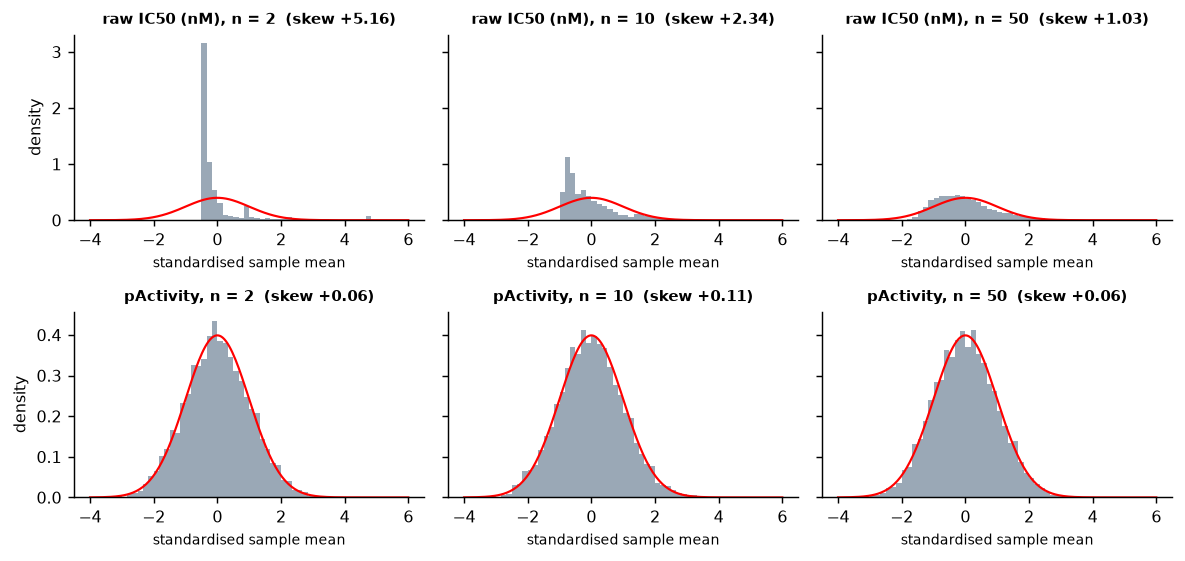

In [9]:
# How fast does the CLT arrive? Same data, two scales, three sample sizes.
fig, axes = plt.subplots(2, 3, figsize=(9.2, 4.4), sharey="row")
for row, (data, label) in enumerate([(ic50_nM, "raw IC50 (nM)"), (exact["pActivity"].to_numpy(), "pActivity")]):
    for col, n in enumerate([2, 10, 50]):
        m = rng.choice(data, size=(6000, n), replace=True).mean(axis=1)
        z = (m - data.mean()) / (data.std(ddof=1) / np.sqrt(n))
        ax = axes[row, col]
        ax.hist(z, bins=60, range=(-4, 6), density=True, color="#89a", alpha=0.85)
        xs = np.linspace(-4, 6, 200)
        ax.plot(xs, stats.norm.pdf(xs), "r-", lw=1.2)
        ax.set_title(f"{label}, n = {n}  (skew {stats.skew(m):+.2f})", fontsize=8.5)
        ax.set_xlabel("standardised sample mean", fontsize=8)
axes[0, 0].set_ylabel("density"); axes[1, 0].set_ylabel("density")
fig.tight_layout()
for data, label in [(ic50_nM, "raw IC50"), (exact["pActivity"].to_numpy(), "pActivity")]:
    sk = [stats.skew(rng.choice(data, size=(6000, n), replace=True).mean(axis=1)) for n in (2, 10, 50, 200)]
    print("%-10s skew of the sample mean at n = 2, 10, 50, 200:" % label, np.round(sk, 2))

<p class="caption"><b>Figure 5.</b> Standardised sampling distributions of the mean, with the standard normal density in red. Top row: for raw IC50 values the sampling distribution is still visibly right-skewed at n = 50, and even at n = 200 (printed) the skew has not vanished, because a single 50 µM compound can dominate the average. Bottom row: on the pActivity scale the approximation is already decent at n = 10. The log transform makes the ordinary machinery of means and intervals <em>valid at the sample sizes we actually have</em>.</p>

This is the practical justification for the transform, independent of the chemical argument in §4. A t-test, a confidence interval and a linear model all lean on the approximate normality of an average; on the raw scale that lean is unsupported for realistic series sizes, and on the log scale it is safe.

## 7. Confidence intervals from a formula, and whether they work

For a mean, the classical 95 % interval is

$$\bar{x}\pm t_{0.975,\,n-1}\cdot\frac{s}{\sqrt{n}},$$

where $s$ is the sample standard deviation and $t$ the Student quantile — the normal quantile 1.96 inflated to account for having estimated $\sigma$ from the same small sample<sup class="c"><a href="#r7">[7]</a></sup>. **A 95 % confidence interval is a statement about the procedure, not about the particular interval**: if the whole experiment were repeated many times, 95 % of the intervals constructed this way would contain the true value. The interval in front of you either contains it or does not.

That promise is conditional on assumptions, so it should be *checked* rather than believed. The next cell checks it by simulation, which is the honest way to find out whether a procedure works on data like yours.

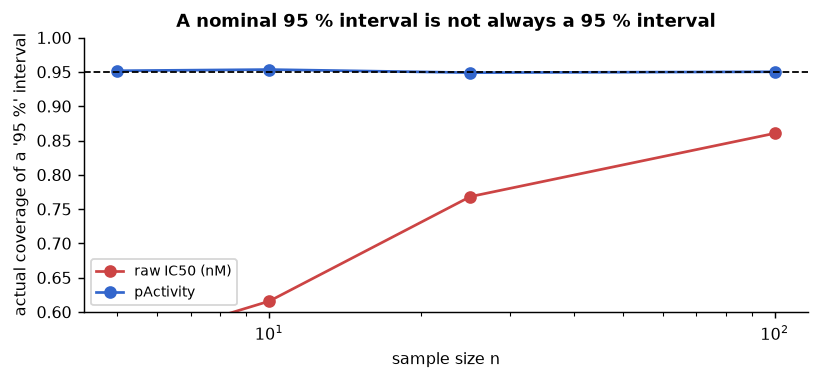

,n,coverage_raw_IC50,coverage_pActivity,mean_width_pActivity
0,5,0.548,0.952,2.625
1,10,0.616,0.954,1.559
2,25,0.768,0.949,0.905
3,100,0.860,0.950,0.440


In [10]:
# Does the textbook 95 % interval actually cover 95 % of the time? Check on both scales.
def covers(data, n, n_rep=4000, truth=None):
    truth = data.mean() if truth is None else truth
    s = rng.choice(data, size=(n_rep, n), replace=True)
    m, sd = s.mean(axis=1), s.std(axis=1, ddof=1)
    half = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return float(np.mean((m - half <= truth) & (truth <= m + half))), float(np.mean(2 * half))

rows = []
for n in (5, 10, 25, 100):
    c_raw, w_raw = covers(ic50_nM, n)
    c_log, w_log = covers(exact["pActivity"].to_numpy(), n)
    rows.append({"n": n, "coverage_raw_IC50": c_raw, "coverage_pActivity": c_log,
                 "mean_width_pActivity": round(w_log, 3)})
cov = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(cov.n, cov.coverage_raw_IC50, "o-", color="#c44", label="raw IC50 (nM)")
ax.plot(cov.n, cov.coverage_pActivity, "o-", color="#36c", label="pActivity")
ax.axhline(0.95, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("sample size n"); ax.set_ylabel("actual coverage of a '95 %' interval")
ax.set_ylim(0.6, 1.0); ax.set_title("A nominal 95 % interval is not always a 95 % interval"); ax.legend(fontsize=7.5)
fig.tight_layout()
cov.round(3)

<p class="caption"><b>Figure 6.</b> Actual coverage of the nominal 95 % Student interval, measured by resampling from the real data. On the pActivity scale coverage is within about one percentage point of 95 % from n = 5 upwards. On the raw IC50 scale it is far too low at small n — around three quarters of the intervals miss the mean at n = 5 — and is still short of 95 % at n = 100. The reason is the skew of Figure 5: the sample mean and the sample standard deviation are positively correlated for right-skewed data, so the samples that land low also get short intervals.</p>

The table under the figure also shows the second thing an interval must be judged on: its **width**. A procedure can achieve perfect coverage by being uselessly wide. Coverage and width together define a confidence procedure, and the bootstrap of the next section is attractive precisely because it buys better coverage at nearly the same width.

<div class="box key"><h4>What to report</h4>
<p>Report the estimate, the interval and the n: "median pActivity 7.52 (95 % CI 7.39–7.65; n = 207 compounds)". Never report a mean with a standard deviation when the reader wants to know about the mean — the SD describes the spread of the <em>data</em>, the SE describes the spread of the <em>estimate</em>, and they differ by a factor √n<sup class="c"><a href="#r11">[11]</a></sup>. Error bars in figures must state which of the two they are<sup class="c"><a href="#r12">[12]</a></sup><sup class="c"><a href="#r13">[13]</a></sup>, and the convention in the journals this group publishes in is the 95 % CI<sup class="c"><a href="#r14">[14]</a></sup><sup class="c"><a href="#r15">[15]</a></sup>.</p></div>

## 8. The bootstrap

The formula above exists only for a handful of estimators. There is no textbook standard error for a median, for a Spearman correlation, for the area under a ROC curve or for the difference in R² between two models — and those are the quantities we actually report. The **bootstrap**<sup class="c"><a href="#r16">[16]</a></sup> solves all of them with one idea: the sample is the best available picture of the population, so resample *from the sample*, with replacement, as many times as the original size, recompute the estimator on each resample, and use the spread of those values as the sampling distribution.

Written out, for $B$ resamples:

1. draw $x^{*}_{1},\dots,x^{*}_{n}$ uniformly with replacement from the observed $x_{1},\dots,x_{n}$;
2. compute $\hat\theta^{*}_{b}$, the estimator applied to that resample;
3. repeat for $b = 1,\dots,B$ (use $B \ge 2{,}000$ for an interval);
4. the **percentile interval** is the 2.5th and 97.5th percentiles of the $\hat\theta^{*}$ values.

We apply it to the question a medicinal chemist actually asks: is the large benzamide–pyrazole series more potent than the second series, and by how much?

series 1 median 7.521  95% CI [7.405, 7.648]  n = 207
series 2 median 6.227  95% CI [5.674, 6.420]  n = 59
difference of medians 1.294  95% CI [1.059, 1.851]


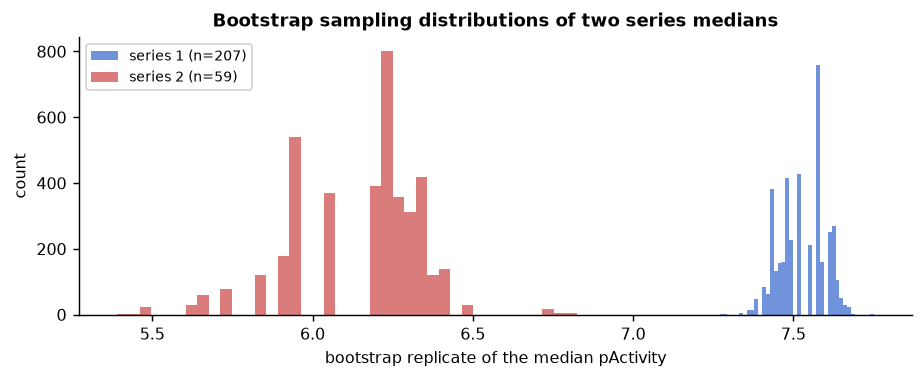

In [11]:
# Bootstrap the median pActivity of the two largest Bemis-Murcko scaffold series.
counts = exact["scaffold_smiles"].value_counts()
s1_smi, s2_smi = counts.index[0], counts.index[1]
s1 = exact.loc[exact.scaffold_smiles == s1_smi, "pActivity"].to_numpy()
s2 = exact.loc[exact.scaffold_smiles == s2_smi, "pActivity"].to_numpy()

def boot_percentile(x, stat=np.median, B=4000, seed=0):
    g = np.random.default_rng(seed)
    idx = g.integers(0, len(x), size=(B, len(x)))
    reps = stat(x[idx], axis=1)
    return reps, np.percentile(reps, [2.5, 97.5])

rep1, ci1 = boot_percentile(s1)
rep2, ci2 = boot_percentile(s2)
diff = rep1 - rep2
ci_d = np.percentile(diff, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.hist(rep1, bins=40, alpha=0.7, color="#36c", label=f"series 1 (n={len(s1)})")
ax.hist(rep2, bins=40, alpha=0.7, color="#c44", label=f"series 2 (n={len(s2)})")
ax.set_xlabel("bootstrap replicate of the median pActivity"); ax.set_ylabel("count")
ax.set_title("Bootstrap sampling distributions of two series medians"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("series 1 median %.3f  95%% CI [%.3f, %.3f]  n = %d" % (np.median(s1), *ci1, len(s1)))
print("series 2 median %.3f  95%% CI [%.3f, %.3f]  n = %d" % (np.median(s2), *ci2, len(s2)))
print("difference of medians %.3f  95%% CI [%.3f, %.3f]" % (np.median(s1) - np.median(s2), *ci_d))

<p class="caption"><b>Figure 7.</b> Bootstrap sampling distributions of the median pActivity of the two largest scaffold series, 4,000 resamples each. The clouds barely overlap: series 1 (about 207 compounds, median near 7.5) is roughly 1.3 log units — a factor of about twenty in concentration — more potent than series 2 (about 59 compounds, median near 6.2), with a 95 % interval for the difference that excludes zero comfortably. Note the visible granularity of the series-2 distribution: a bootstrap median can only take values that are present in the sample, so with 59 observations the replicate distribution is discrete. That is a real feature of bootstrapping order statistics, not a plotting artefact.</p>

The percentile interval is simple but slightly biased when the estimator's sampling distribution is skewed or when its spread depends on the parameter value. The **bias-corrected and accelerated (BCa)** interval<sup class="c"><a href="#r17">[17]</a></sup><sup class="c"><a href="#r18">[18]</a></sup> corrects both: a bias-correction term $z_0$ from the fraction of bootstrap replicates below the observed estimate, and an acceleration term $a$ from the jackknife skewness. The adjusted percentiles are

$$\alpha_{1,2}=\Phi\!\left(z_{0}+\frac{z_{0}+z_{\alpha/2,\,1-\alpha/2}}{1-a\,(z_{0}+z_{\alpha/2,\,1-\alpha/2})}\right).$$

It is worth implementing once by hand, both to demystify it and because the implementation is six lines.

In [12]:
# BCa by hand, checked against scipy.stats.bootstrap.
def bca_interval(x, stat=np.median, B=4000, alpha=0.05, seed=0):
    g = np.random.default_rng(seed)
    theta_hat = stat(x)
    reps = stat(x[g.integers(0, len(x), size=(B, len(x)))], axis=1)
    z0 = stats.norm.ppf(np.mean(reps < theta_hat))                       # bias correction
    jack = np.array([stat(np.delete(x, i)) for i in range(len(x))])      # jackknife
    d = jack.mean() - jack
    a = (d ** 3).sum() / (6.0 * ((d ** 2).sum() ** 1.5))                 # acceleration
    zs = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    pct = stats.norm.cdf(z0 + (z0 + zs) / (1 - a * (z0 + zs)))
    return np.percentile(reps, 100 * pct), z0, a

(lo, hi), z0, a = bca_interval(s2)
res = stats.bootstrap((s2,), np.median, n_resamples=4000, method="BCa",
                      rng=np.random.default_rng(0), confidence_level=0.95)
print("series 2 median %.3f" % np.median(s2))
print("  percentile CI   [%.3f, %.3f]" % tuple(boot_percentile(s2)[1]))
print("  BCa by hand     [%.3f, %.3f]   (z0 = %+.3f, a = %+.4f)" % (lo, hi, z0, a))
print("  BCa scipy       [%.3f, %.3f]" % (res.confidence_interval.low, res.confidence_interval.high))
print("  Student CI      [%.3f, %.3f]  <- for the MEAN, shown only for scale"
      % tuple(stats.t.interval(0.95, len(s2) - 1, s2.mean(), stats.sem(s2))))

series 2 median 6.227
  percentile CI   [5.674, 6.420]
  BCa by hand     [5.662, 6.398]   (z0 = -0.130, a = -0.0001)
  BCa scipy       [5.674, 6.420]
  Student CI      [5.808, 6.331]  <- for the MEAN, shown only for scale


The hand-written and library intervals agree to within the Monte-Carlo noise of 4,000 resamples, and both differ from the plain percentile interval by a few hundredths of a log unit — small here because the median of 59 values is nearly unbiased, but the correction matters for strongly skewed estimators such as a variance ratio or an enrichment factor.

<div class="box warn"><h4>Where the bootstrap fails</h4>
<p>The bootstrap assumes the sample is representative and the estimator is a smooth function of the distribution. It fails for the <strong>maximum</strong> or the minimum (the resampled maximum can never exceed the observed one), degrades for very small <i>n</i>, and is invalid for <strong>dependent data</strong> unless blocks rather than points are resampled — the situation of molecular-dynamics frames (§12). The next cell exhibits the first failure.</p></div>

population maximum 9.82 | sample maximum 8.22 | bootstrap 95% CI [7.48, 8.22]
distinct values taken by the bootstrapped maximum: 7
population mean    6.508 | sample mean    6.267 | bootstrap 95% CI [5.928, 6.595]


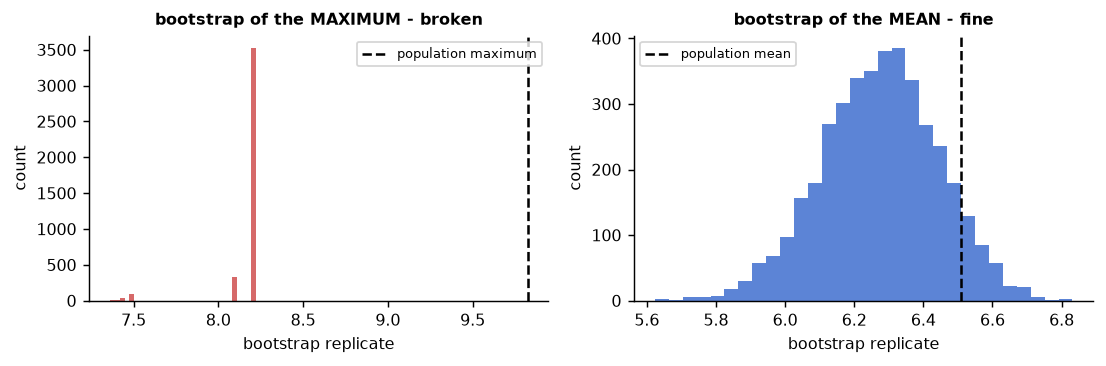

In [13]:
# Failure mode: bootstrapping an extreme. The truth here is known exactly.
true_max = population.max()
small = rng.choice(population, 40, replace=False)       # one study of 40 compounds
reps_max, ci_max = boot_percentile(small, stat=np.max, B=4000, seed=3)
reps_mean, ci_mean = boot_percentile(small, stat=np.mean, B=4000, seed=3)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 2.9))
axes[0].hist(reps_max, bins=30, color="#c44", alpha=0.8)
axes[0].axvline(true_max, color="k", lw=1.4, ls="--", label="population maximum")
axes[0].set_title("bootstrap of the MAXIMUM - broken", fontsize=9); axes[0].legend(fontsize=7)
axes[1].hist(reps_mean, bins=30, color="#36c", alpha=0.8)
axes[1].axvline(population.mean(), color="k", lw=1.4, ls="--", label="population mean")
axes[1].set_title("bootstrap of the MEAN - fine", fontsize=9); axes[1].legend(fontsize=7)
for ax in axes: ax.set_xlabel("bootstrap replicate"); ax.set_ylabel("count")
fig.tight_layout()
print("population maximum %.2f | sample maximum %.2f | bootstrap 95%% CI [%.2f, %.2f]"
      % (true_max, small.max(), *ci_max))
print("distinct values taken by the bootstrapped maximum:", len(np.unique(reps_max)))
print("population mean    %.3f | sample mean    %.3f | bootstrap 95%% CI [%.3f, %.3f]"
      % (population.mean(), small.mean(), *ci_mean))

<p class="caption"><b>Figure 8.</b> Two bootstraps on the same sample of 40 compounds. Left: the bootstrap distribution of the maximum takes only a handful of distinct values, all of them at or below the sample maximum, and the resulting interval excludes the true population maximum entirely — the estimator depends on the extreme tail of the distribution, which resampling cannot reconstruct. Right: the bootstrap of the mean behaves exactly as advertised, covering the population mean. The lesson generalises: before bootstrapping an unfamiliar statistic, ask whether it depends on the bulk of the distribution (safe) or on its edge (unsafe).</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Write a function <code>boot_ci(x, stat, B)</code> and use it on the <b>interquartile range</b> and on the <b>90th percentile</b> of <code>s1</code>. Which of the two gives a smoother bootstrap distribution, and why? Then reduce <code>s1</code> to its first 12 compounds and repeat: at what sample size does the 90th-percentile interval stop being trustworthy?</p></div>

## 9. Robust summaries

A single mistyped value, a compound recorded in µM instead of nM, or one genuinely outlying patient can move an arithmetic mean arbitrarily far. The **breakdown point** of an estimator is the fraction of the sample that must be corrupted before the estimate can be driven to infinity: it is 0 for the mean (one bad value is enough), 0.5 for the median, and $\gamma$ for a $\gamma$-trimmed mean. Robust alternatives<sup class="c"><a href="#r19">[19]</a></sup> cost a little efficiency when the data are clean and save the analysis when they are not:

- **median** — the 50th percentile; breakdown 0.5.
- **MAD** — median absolute deviation, $\operatorname{median}(|x_i - \operatorname{median}(x)|)$, multiplied by 1.4826 so that it estimates σ for normal data<sup class="c"><a href="#r20">[20]</a></sup>.
- **trimmed mean** — discard the lowest and highest γ of the data, average the rest.

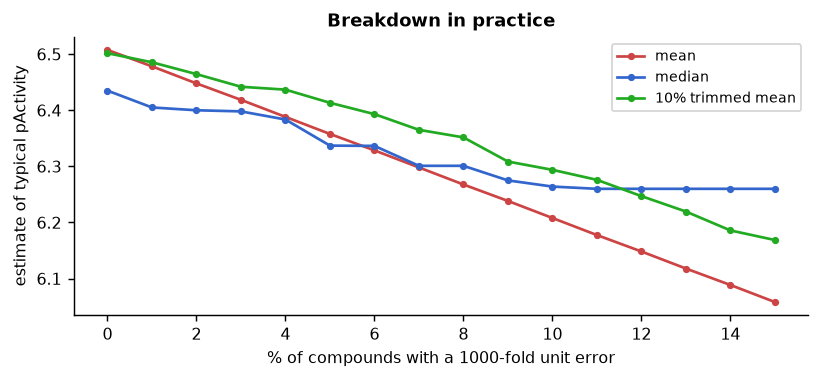

,clean,1% corrupted,shift
mean,6.508,6.478,-0.029
median,6.435,6.400,-0.035
10% trimmed mean,6.502,6.482,-0.020
SD,1.109,1.141,0.032
MAD*1.4826,1.168,1.186,0.019


In [14]:
# What one bad row does to each summary. 1 % of the compounds get a unit error (uM read as nM).
clean = exact["pActivity"].to_numpy().copy()
contaminated = clean.copy()
bad_idx = rng.choice(len(contaminated), size=int(0.01 * len(contaminated)), replace=False)
contaminated[bad_idx] -= 3.0                              # a 1000-fold unit mistake
summaries = {"mean": np.mean, "median": np.median,
             "10% trimmed mean": lambda v: stats.trim_mean(v, 0.1),
             "SD": lambda v: np.std(v, ddof=1),
             "MAD*1.4826": lambda v: 1.4826 * stats.median_abs_deviation(v)}
tab = pd.DataFrame({"clean": {k: f(clean) for k, f in summaries.items()},
                    "1% corrupted": {k: f(contaminated) for k, f in summaries.items()}})
tab["shift"] = tab["1% corrupted"] - tab["clean"]
fracs = np.linspace(0, 0.15, 16)
curves = {k: [] for k in ("mean", "median", "10% trimmed mean")}
for fr in fracs:
    v = clean.copy()
    if fr > 0:
        v[rng.choice(len(v), size=int(fr * len(v)), replace=False)] -= 3.0
    for k in curves: curves[k].append(summaries[k](v))
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for k, c in zip(curves, ["#c44", "#36c", "#2a2"]):
    ax.plot(100 * fracs, curves[k], "o-", ms=3, color=c, label=k)
ax.set_xlabel("% of compounds with a 1000-fold unit error"); ax.set_ylabel("estimate of typical pActivity")
ax.set_title("Breakdown in practice"); ax.legend(fontsize=7.5)
fig.tight_layout()
tab.round(3)

<p class="caption"><b>Figure 9.</b> Each summary of typical potency as the fraction of corrupted rows grows from 0 to 15 %. The mean (red) slides down immediately and linearly — with 10 % of the rows wrong it has lost about 0.3 log units. The 10 % trimmed mean (green) is flat until the contamination reaches its trimming fraction and then collapses. The median (blue) barely moves across the whole range. The table above the figure shows the same effect for the scale estimates: a 1 % contamination inflates the standard deviation noticeably while the MAD-based estimate is almost unchanged.</p>

This is not an argument for always reporting medians: the mean is efficient on clean symmetric data and is what every linear model estimates. The argument is for knowing which you reported and why, and for checking that the two agree — a large gap between mean and median is a diagnostic that the column needs looking at.

## 10. Correlation, and three ways to measure it

Correlation is the most over-interpreted statistic in applied science, so it pays to be precise about what each coefficient measures.

- **Pearson's $r$** measures the strength of the *linear* relationship; it is sensitive to outliers and to monotone non-linearity.
- **Spearman's $\rho$** is Pearson's $r$ on the *ranks*: monotone association of any shape, insensitive to outliers in value.
- **Kendall's $\tau$** counts concordant minus discordant pairs; it is the most interpretable (the rescaled probability that two compounds are ordered the same way by both variables) and the most stable in small samples.

For a confidence interval, Pearson's $r$ has the Fisher $z$ transform, $z=\operatorname{artanh}(r)$, which is approximately normal with standard error $1/\sqrt{n-3}$; for the rank coefficients the bootstrap is the practical route<sup class="c"><a href="#r21">[21]</a></sup><sup class="c"><a href="#r22">[22]</a></sup>.

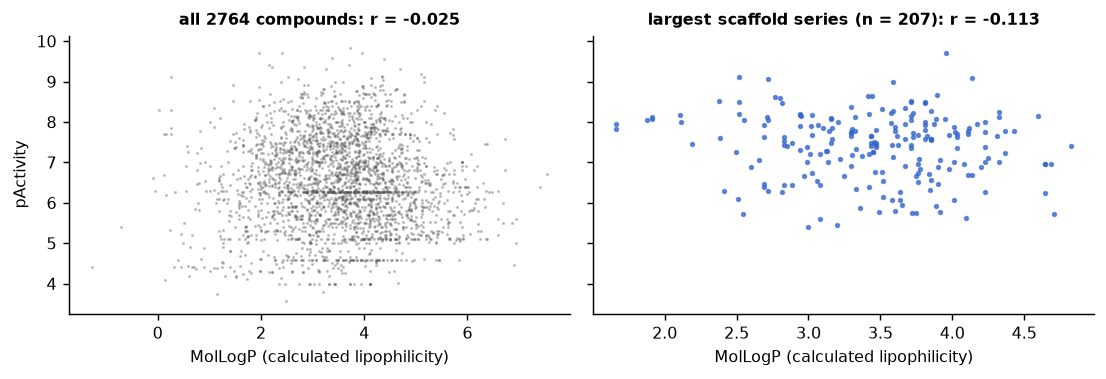

,n,pearson_r,r_CI_low,r_CI_high,p_pearson,spearman,rho_CI_low,rho_CI_high,kendall
set,,,,,,,,,
all exact compounds,2764,-0.0253,-0.0625,0.0120,0.1836,-0.0546,-0.0916,-0.0164,-0.0364
largest series only,207,-0.1126,-0.2452,0.0241,0.1062,-0.1042,-0.2347,0.0370,-0.0670


In [15]:
# Lipophilicity vs potency: globally, and inside a single congeneric series.
def corr_table(x, y, label, B=3000, seed=0):
    g = np.random.default_rng(seed)
    n = len(x)
    r, pr = stats.pearsonr(x, y); rho, prho = stats.spearmanr(x, y); tau, ptau = stats.kendalltau(x, y)
    z = np.arctanh(r); se = 1 / np.sqrt(n - 3)
    ci_r = np.tanh([z - 1.96 * se, z + 1.96 * se])
    idx = g.integers(0, n, size=(B, n))
    ci_rho = np.percentile([stats.spearmanr(x[i], y[i]).statistic for i in idx], [2.5, 97.5])
    return {"set": label, "n": n, "pearson_r": r, "r_CI_low": ci_r[0], "r_CI_high": ci_r[1],
            "p_pearson": pr, "spearman": rho, "rho_CI_low": ci_rho[0], "rho_CI_high": ci_rho[1],
            "kendall": tau}

rows = [corr_table(exact.MolLogP.to_numpy(), exact.pActivity.to_numpy(), "all exact compounds")]
sub = exact.loc[exact.scaffold_smiles == s1_smi]
rows.append(corr_table(sub.MolLogP.to_numpy(), sub.pActivity.to_numpy(), "largest series only"))
ctab = pd.DataFrame(rows).set_index("set")
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.0), sharey=True)
axes[0].plot(exact.MolLogP, exact.pActivity, ".", ms=1.5, alpha=0.3, color="#555")
axes[0].set_title("all %d compounds: r = %.3f" % (len(exact), ctab.pearson_r.iloc[0]), fontsize=9)
axes[1].plot(sub.MolLogP, sub.pActivity, ".", ms=4, alpha=0.7, color="#36c")
axes[1].set_title("largest scaffold series (n = %d): r = %.3f" % (len(sub), ctab.pearson_r.iloc[1]), fontsize=9)
for ax in axes: ax.set_xlabel("MolLogP (calculated lipophilicity)")
axes[0].set_ylabel("pActivity")
fig.tight_layout()
ctab.round(4)

<p class="caption"><b>Figure 10.</b> Calculated lipophilicity against potency, for all 2,764 measured compounds (left) and for the single largest congeneric series (right). The global Pearson correlation is essentially zero — about −0.03, with a 95 % interval that straddles zero — and the Spearman coefficient, about −0.05, is "statistically significant" at p below 0.01 purely because n is large. Inside the series the coefficient is around −0.11 with a wide interval. The honest reading is: <strong>lipophilicity carries no useful univariate information about ROCK1 potency in this dataset</strong>, and the significant global Spearman value is an illustration of the gap between significance and importance that Unit 8 develops.</p>

Two habits follow. Always report the interval next to the coefficient: "ρ = −0.05 (95 % CI −0.09 to −0.02, n = 2,764)" makes the irrelevance visible in a way that "ρ = −0.05, p = 0.004" does not. And always plot the data. Anscombe's quartet<sup class="c"><a href="#r23">[23]</a></sup> and its modern successors<sup class="c"><a href="#r24">[24]</a></sup> are four datasets with identical means, variances and correlations and utterly different shapes; the next cell reproduces them from their published values so that the point is in your own notebook.

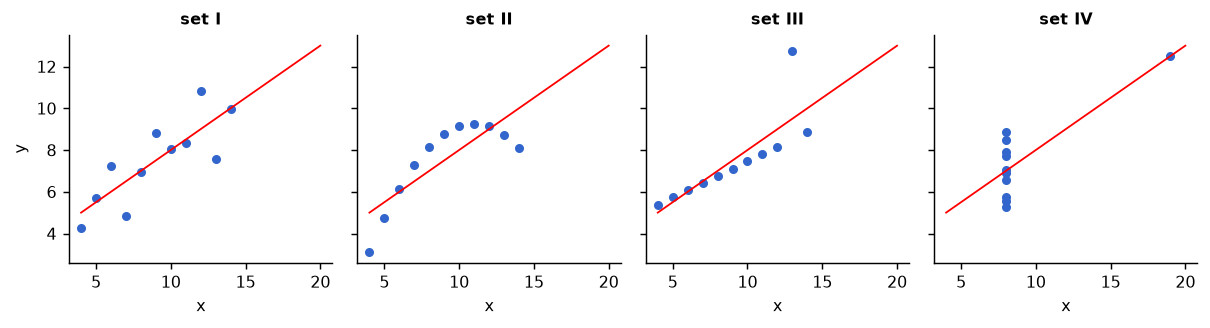

,mean_x,mean_y,sd_y,pearson,spearman,slope
set,,,,,,
I,9.0,7.501,2.032,0.816,0.818,0.5
II,9.0,7.501,2.032,0.816,0.691,0.5
III,9.0,7.500,2.030,0.816,0.991,0.5
IV,9.0,7.501,2.031,0.817,0.500,0.5


In [16]:
# Anscombe's quartet: identical summary statistics, four different stories.
x1 = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], float)
quartet = {
    "I":   (x1, np.array([8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68])),
    "II":  (x1, np.array([9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74])),
    "III": (x1, np.array([7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73])),
    "IV":  (np.array([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], float),
            np.array([6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89])),
}
fig, axes = plt.subplots(1, 4, figsize=(9.4, 2.6), sharex=True, sharey=True)
summ = []
for ax, (k, (xx, yy)) in zip(axes, quartet.items()):
    ax.plot(xx, yy, "o", ms=4, color="#36c")
    b, a = np.polyfit(xx, yy, 1)
    ax.plot([4, 20], [a + b * 4, a + b * 20], "r-", lw=1)
    ax.set_title("set %s" % k, fontsize=9); ax.set_xlabel("x")
    summ.append({"set": k, "mean_x": xx.mean(), "mean_y": yy.mean(), "sd_y": yy.std(ddof=1),
                 "pearson": stats.pearsonr(xx, yy).statistic,
                 "spearman": stats.spearmanr(xx, yy).statistic, "slope": b})
axes[0].set_ylabel("y")
fig.tight_layout()
pd.DataFrame(summ).set_index("set").round(3)

<p class="caption"><b>Figure 11.</b> Anscombe's four datasets. All four share a mean x of 9, a mean y near 7.5, a Pearson correlation near 0.816 and the same fitted line (printed in the table), yet only set I is a plausible linear relationship: set II is a parabola, set III is a perfect line with one outlier, and set IV has no x variation at all except for one leverage point that determines the entire fit. Note that the Spearman coefficients <em>do</em> differ between the sets — rank correlation is not fooled in the same way — which is a small argument for reporting both.</p>

## 11. The experimental noise floor of a bioactivity dataset

A model cannot predict a measurement more precisely than the measurement can reproduce itself. Before any modelling in Units 11–17, it is worth knowing what that limit is for our data, and the curated table lets us estimate it directly: 492 compounds were measured more than once, often in different laboratories and different publications, and the column `pActivity_sd` records the spread of those repeats.

compounds with >= 2 exact measurements : 337
  of these, with non-zero spread       : 161  (the rest report identical values)
  median within-compound SD (spread>0) : 0.302 log units
  pooled within-compound SD            : 0.406 log units
  compounds flagged wide_spread (>1 log): 60
  largest observed range               : 3.30 log units

spread of the target itself (SD)       : 1.109 log units
implied ceiling on R^2 for ANY model   : 0.866
implied floor on RMSE                  : 0.406 log units


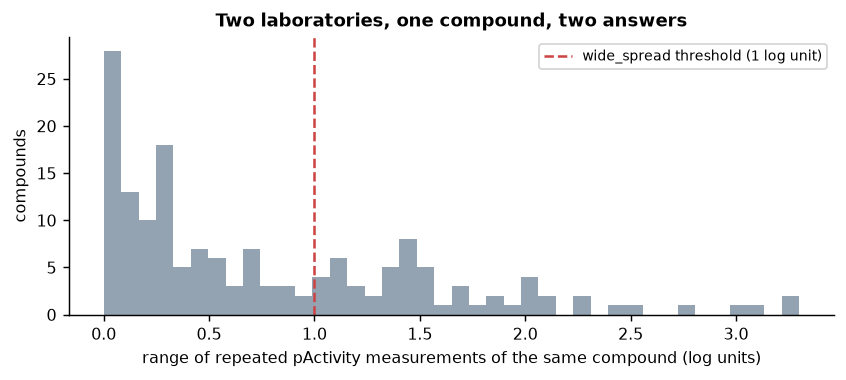

In [17]:
# How reproducible is a public potency value? The replicate spread, and what it implies.
rep = rock.loc[(rock["n_exact"] >= 2) & (~rock["censored"])]
spread = rep.loc[rep["pActivity_range"] > 0]
pooled_sd = np.sqrt(np.nanmean(rep["pActivity_sd"].to_numpy() ** 2))      # pooled over all repeated compounds
total_sd = exact["pActivity"].std(ddof=1)
print("compounds with >= 2 exact measurements : %d" % len(rep))
print("  of these, with non-zero spread       : %d  (the rest report identical values)" % len(spread))
print("  median within-compound SD (spread>0) : %.3f log units" % spread["pActivity_sd"].median())
print("  pooled within-compound SD            : %.3f log units" % pooled_sd)
print("  compounds flagged wide_spread (>1 log): %d" % int(rock["wide_spread"].sum()))
print("  largest observed range               : %.2f log units" % rep["pActivity_range"].max())
print("\nspread of the target itself (SD)       : %.3f log units" % total_sd)
print("implied ceiling on R^2 for ANY model   : %.3f" % (1 - pooled_sd ** 2 / total_sd ** 2))
print("implied floor on RMSE                  : %.3f log units" % pooled_sd)

fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.hist(spread["pActivity_range"], bins=40, color="#89a", alpha=0.9)
ax.axvline(1.0, color="#c44", lw=1.4, ls="--", label="wide_spread threshold (1 log unit)")
ax.set_xlabel("range of repeated pActivity measurements of the same compound (log units)")
ax.set_ylabel("compounds"); ax.set_title("Two laboratories, one compound, two answers"); ax.legend(fontsize=7.5)
fig.tight_layout()

<p class="caption"><b>Figure 12.</b> Distribution of the within-compound range for the compounds measured more than once with a non-zero spread. The median range is around half a log unit — a factor of three in concentration — and a long tail reaches beyond three log units, i.e. a thousand-fold disagreement between two published values for the same molecule. Sixty compounds exceed the one-log-unit flag that the curation protocol sets.</p>

The two numbers printed above the figure are the ones to remember when a reviewer asks why a QSAR model "only" reaches R² of 0.6. With a pooled within-compound standard deviation of about 0.4 log units against a total target spread of about 1.1, a perfect model that predicted the *true* potency of every compound exactly would still score an R² of roughly 0.85 against these labels, and could not achieve an RMSE below about 0.4. Independent analyses of public ChEMBL data reach the same order of magnitude — around 0.5 log units for mixed public IC50 data<sup class="c"><a href="#r25">[25]</a></sup> and about 0.44 for heterogeneous Ki data<sup class="c"><a href="#r26">[26]</a></sup>.

Three honest caveats belong with that estimate, and stating them is part of the craft:

1. Only 337 compounds have two or more exact measurements, and about half of those report *identical* values — often the same primary measurement propagated through several papers rather than an independent repeat. Including them pulls the pooled estimate down; the median over compounds with genuinely different values, about 0.3 log units, is the alternative, and the truth lies between them.
2. Re-measured compounds are not a random sample: they are reference inhibitors, clinical compounds and series anchors, so the estimate may not transfer to a singleton in the tail of the table.
3. The tabulated target is the *median* of the available measurements, so its error is smaller than a single assay's by roughly √n for well-measured compounds.

<div class="box key"><h4>The rule</h4>
<p>Estimate the noise floor of your labels before you tune a model, quote it in the paper, and compare every performance claim to it. A model whose RMSE equals the assay's reproducibility is as good as the data allow; a model whose cross-validated RMSE is <em>below</em> the noise floor is evidence of leakage, not of genius.</p></div>

## 12. When n is not n: correlated samples

Everything above assumed independent draws. Molecular-dynamics frames are not independent: the structure at 402 ps is nearly the structure at 400 ps. The consequence is severe and widely ignored — a 1 ns trajectory saved every 2 ps looks like 500 measurements, so the naive standard error σ/√500 is tiny, and the resulting interval can be an order of magnitude too narrow.

<div class="box bridge"><h4>Domain context — what a molecular-dynamics trajectory is</h4>
<p>A <strong>molecular-dynamics (MD) simulation</strong> integrates Newton's equations for every atom of a protein surrounded by explicit water, in steps of about 2 femtoseconds, and writes the coordinates to disk every few picoseconds. Our frozen dataset holds six 1 ns simulations of the <strong>Trp-cage</strong> miniprotein (PDB 1L2Y, 20 residues)<sup class="c"><a href="#r27">[27]</a></sup> run with OpenMM<sup class="c"><a href="#r28">[28]</a></sup> and the AMBER ff14SB force field<sup class="c"><a href="#r29">[29]</a></sup>: three replicas at 300 K (condition A) and three at 340 K (condition B), differing only in their random seed. The <strong>C-alpha RMSD</strong> is the root-mean-square deviation of the backbone from the starting structure after optimal superposition, in nanometres — the standard scalar summary of "how far the protein has moved". A <strong>replica</strong> is an independent repetition of the same simulation with a different seed; replicas, not frames, are the independent experimental units, which is the whole point of this section and the centrepiece of Unit 8.</p></div>

The tool is the **autocorrelation function** $C(\Delta)$ of the time series and its integral, the **integrated autocorrelation time** $\tau_{\text{int}}$. The effective number of independent samples in a run of length $T$ saved every $\Delta t$ is approximately $n_{\text{eff}} = T / (2\tau_{\text{int}})$, and the correct standard error is $\sigma/\sqrt{n_{\text{eff}}}$, not $\sigma/\sqrt{n}$<sup class="c"><a href="#r30">[30]</a></sup><sup class="c"><a href="#r31">[31]</a></sup>. The same autocorrelation machinery also decides how much of the beginning of a run to discard as equilibration, for which automated criteria exist<sup class="c"><a href="#r32">[32]</a></sup>; Unit 20 applies them.

run A2: 500 frames, mean RMSD 0.1595 nm, SD 0.0110 nm
integrated autocorrelation time tau_int = 18 ps -> n_eff = 28.2 independent samples
  naive SE  sigma/sqrt(500)      : 0.00049 nm
  corrected SE sigma/sqrt(n_eff) : 0.00206 nm
  10-block SE                    : 0.00173 nm


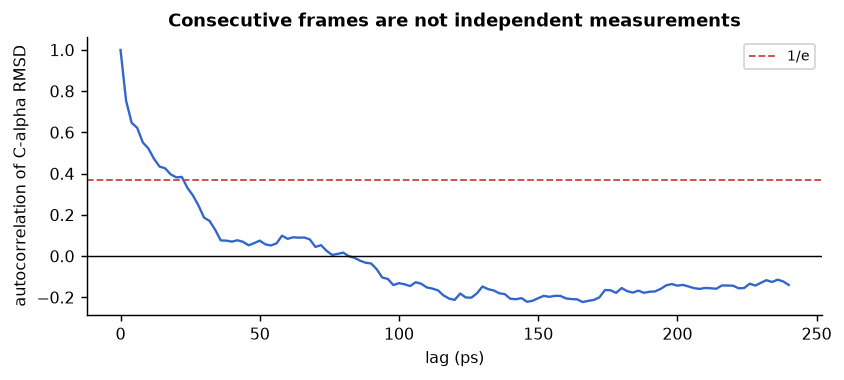

In [18]:
# Autocorrelation, tau_int and the three standard errors of one MD observable.
def acf(x, nlags=120):
    x = x - x.mean()
    full = np.correlate(x, x, mode="full")[len(x) - 1:]
    return full[: nlags + 1] / full[0]

def tau_int(x):
    c = acf(x, nlags=len(x) // 4)
    first_neg = np.argmax(c < 0) if (c < 0).any() else len(c)
    return 0.5 + c[1:first_neg].sum()            # in units of the saving interval

def block_se(x, n_blocks=10):
    b = x[: (len(x) // n_blocks) * n_blocks].reshape(n_blocks, -1).mean(axis=1)
    return b.std(ddof=1) / np.sqrt(n_blocks)

run = md_obs.query("condition == 'A' and replica == 2")["rmsd_ca_nm"].to_numpy()
dt = 2.0                                          # ps between saved frames
tau = tau_int(run) * dt
fig, ax = plt.subplots(figsize=(6.6, 3.0))
lags = np.arange(121) * dt
ax.plot(lags, acf(run, 120), lw=1.3, color="#36c")
ax.axhline(0, color="k", lw=0.8); ax.axhline(1 / np.e, color="#c44", ls="--", lw=1, label="1/e")
ax.set_xlabel("lag (ps)"); ax.set_ylabel("autocorrelation of C-alpha RMSD")
ax.set_title("Consecutive frames are not independent measurements"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("run A2: %d frames, mean RMSD %.4f nm, SD %.4f nm" % (len(run), run.mean(), run.std(ddof=1)))
print("integrated autocorrelation time tau_int = %.0f ps -> n_eff = %.1f independent samples"
      % (tau, 1000 / (2 * tau)))
print("  naive SE  sigma/sqrt(500)      : %.5f nm" % (run.std(ddof=1) / np.sqrt(len(run))))
print("  corrected SE sigma/sqrt(n_eff) : %.5f nm" % (run.std(ddof=1) / np.sqrt(1000 / (2 * tau))))
print("  10-block SE                    : %.5f nm" % block_se(run))

<p class="caption"><b>Figure 13.</b> Autocorrelation of the C-alpha RMSD of run A2 against lag. The correlation does not reach zero until a lag of several tens of picoseconds, which means that frames saved 2 ps apart carry almost the same information. The integrated autocorrelation time of this run, estimated by summing the autocorrelation function to its first zero crossing, is about 18 ps, so a 1 ns trajectory contains roughly thirty effectively independent samples, not five hundred. The three standard errors printed below the figure differ by about a factor of four, and the naive one is the smallest — which is why it is the one most often reported.</p>

Writing σ/√500 instead of σ/√n<sub>eff</sub> understates the uncertainty of a simulation average by the factor √(2τ<sub>int</sub>/Δt), between about 4 and 9 for the six runs printed above. The cleanest way to count samples correctly is not to count frames at all, but to treat each **replica** as one measurement.

condition A replica means (nm): [0.1098 0.1595 0.2515]  -> mean 0.1736, SE 0.0415
condition B replica means (nm): [0.1211 0.1884 0.1504]  -> mean 0.1533, SE 0.0195
95% half-width: naive 0.0031 | tau-corrected 0.0180 | replica-level 0.0813 nm
ratio replica-level / naive: 26.4 x wider
tau_int per run (ps): {'A1': np.float64(62.9), 'A2': np.float64(17.7), 'A3': np.float64(21.4), 'B1': np.float64(17.7), 'B2': np.float64(80.2), 'B3': np.float64(61.5)}
n_eff per run        : {'A1': np.float64(7.9), 'A2': np.float64(28.2), 'A3': np.float64(23.4), 'B1': np.float64(28.2), 'B2': np.float64(6.2), 'B3': np.float64(8.1)}


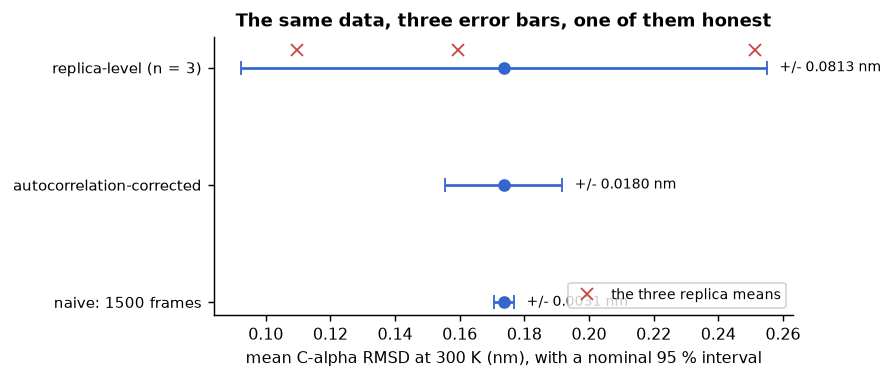

In [19]:
# Three ways to put an error bar on 'the RMSD at 300 K', from most wrong to least wrong.
per_run = (md_obs.groupby(["condition", "replica"], observed=True)["rmsd_ca_nm"]
           .agg(["mean", "std", "count"]).reset_index())
A = per_run.loc[per_run.condition == "A", "mean"].to_numpy()
B = per_run.loc[per_run.condition == "B", "mean"].to_numpy()
frames_A = md_obs.loc[md_obs.condition == "A", "rmsd_ca_nm"].to_numpy()
se_naive = frames_A.std(ddof=1) / np.sqrt(len(frames_A))
tau_A = np.mean([tau_int(md_obs.loc[(md_obs.condition == "A") & (md_obs.replica == r), "rmsd_ca_nm"].to_numpy()) * 2.0
                 for r in (1, 2, 3)])
se_tau = frames_A.std(ddof=1) / np.sqrt(3 * 1000 / (2 * tau_A))
se_rep = A.std(ddof=1) / np.sqrt(3)

fig, ax = plt.subplots(figsize=(7.0, 3.0))
labels = ["naive: 1500 frames", "autocorrelation-corrected", "replica-level (n = 3)"]
for i, (se, lab) in enumerate(zip([se_naive, se_tau, se_rep], labels)):
    ax.errorbar(A.mean(), i, xerr=1.96 * se, fmt="o", color="#36c", capsize=4)
    ax.text(A.mean() + 1.96 * se + 0.004, i, "+/- %.4f nm" % (1.96 * se), va="center", fontsize=8)
ax.plot(A, [2.15] * 3, "x", color="#c44", ms=7, label="the three replica means")
ax.set_yticks(range(3)); ax.set_yticklabels(labels, fontsize=8.5)
ax.set_xlabel("mean C-alpha RMSD at 300 K (nm), with a nominal 95 % interval")
ax.set_title("The same data, three error bars, one of them honest"); ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
print("condition A replica means (nm):", np.round(A, 4), " -> mean %.4f, SE %.4f" % (A.mean(), se_rep))
print("condition B replica means (nm):", np.round(B, 4), " -> mean %.4f, SE %.4f" % (B.mean(), B.std(ddof=1) / np.sqrt(3)))
print("95%% half-width: naive %.4f | tau-corrected %.4f | replica-level %.4f nm"
      % (1.96 * se_naive, 1.96 * se_tau, 1.96 * se_rep))
print("ratio replica-level / naive: %.1f x wider" % (se_rep / se_naive))
per_tau = {f"{c}{r}": round(tau_int(md_obs.loc[(md_obs.condition == c) & (md_obs.replica == r),
                                               "rmsd_ca_nm"].to_numpy()) * 2.0, 1)
           for c in ("A", "B") for r in (1, 2, 3)}
print("tau_int per run (ps):", per_tau)
print("n_eff per run        :", {k: round(1000 / (2 * v), 1) for k, v in per_tau.items()})

<p class="caption"><b>Figure 14.</b> The mean C-alpha RMSD of the three 300 K runs with three different error bars. The naive interval built from 1,500 frames is about ±0.003 nm; correcting for autocorrelation widens it roughly sixfold; the replica-level interval, built from the three run means (red crosses, 0.110, 0.160 and 0.252 nm), is about ±0.08 nm — the only one that contains all three replicas. The runs disagree with each other far more than the frames within a run do, because each explores a different region of conformational space in 1 ns.</p>

The replica-level standard error is the honest one because it is the only one whose "repeat the experiment" matches what we would actually repeat. This is the statistical statement of a principle with a name — **pseudoreplication**<sup class="c"><a href="#r33">[33]</a></sup>, measuring the same experimental unit many times and counting the measurements as independent samples — and Unit 8 turns it into the unit's centrepiece experiment by running the same comparison at frame level and at replica level and getting p-values that differ by twenty-five orders of magnitude.

## 13. Putting it together: how the group reports an estimate

Every table and every figure in a manuscript from this laboratory should be reducible to the pattern below: an estimate, an interval, the n that produced it, and a statement of which source of variability the interval covers.

In [20]:
# A small reporting table of the kind that goes into a paper, every row with an interval.
def ci_mean(x):
    return stats.t.interval(0.95, len(x) - 1, np.mean(x), stats.sem(x))

def ci_boot(x, stat, B=4000, seed=0):
    g = np.random.default_rng(seed)
    reps = stat(x[g.integers(0, len(x), size=(B, len(x)))], axis=1)
    return tuple(np.percentile(reps, [2.5, 97.5]))

rows = [
    ("mean pActivity, all exact compounds", exact.pActivity.mean(), *ci_mean(exact.pActivity.to_numpy()),
     len(exact), "sampling only (parametric t)"),
    ("median pActivity, series 1", np.median(s1), *ci_boot(s1, np.median), len(s1), "sampling only (bootstrap)"),
    ("median pActivity, series 2", np.median(s2), *ci_boot(s2, np.median), len(s2), "sampling only (bootstrap)"),
    ("Spearman rho, cLogP vs pActivity", stats.spearmanr(exact.MolLogP, exact.pActivity).statistic,
     *ctab.loc["all exact compounds", ["rho_CI_low", "rho_CI_high"]].to_numpy(), len(exact), "sampling only (bootstrap)"),
    ("mean C-alpha RMSD at 300 K (nm)", A.mean(), A.mean() - 1.96 * se_rep, A.mean() + 1.96 * se_rep,
     3, "between-replica (n = 3 runs)"),
]
report = pd.DataFrame(rows, columns=["quantity", "estimate", "ci_low", "ci_high", "n", "interval covers"])
report["estimate"] = report["estimate"].round(3); report[["ci_low", "ci_high"]] = report[["ci_low", "ci_high"]].round(3)
report

,quantity,estimate,ci_low,ci_high,n,interval covers
0,"mean pActivity, all exact compounds",6.508,6.466,6.549,2764,sampling only (parametric t)
1,"median pActivity, series 1",7.521,7.405,7.648,207,sampling only (bootstrap)
2,"median pActivity, series 2",6.227,5.674,6.420,59,sampling only (bootstrap)
3,"Spearman rho, cLogP vs pActivity",-0.055,-0.092,-0.016,2764,sampling only (bootstrap)
4,mean C-alpha RMSD at 300 K (nm),0.174,0.092,0.255,3,between-replica (n = 3 runs)


Read the last column as carefully as the first. None of these intervals covers the measurement error quantified in §11, and the last one covers between-replica variability but not force-field error. An interval is always an interval *with respect to a specified repetition*, and naming that repetition is part of reporting the number.

<div class="box bridge"><h4>Bridge</h4>
<p>This unit is the foundation of the statistics block. <a href="../U8_Hypothesis_Testing/index.html">Unit 8</a> turns intervals into tests, effect sizes and multiplicity corrections, and reuses both the scaffold-series comparison and the replica MD data of this unit; <a href="../U9_Linear_Models/index.html">Unit 9</a> puts the same inference machinery inside a regression; <a href="../U10_Bayesian/index.html">Unit 10</a> re-derives intervals as statements about parameters rather than about procedures. Forward, <a href="../U12_Validation/index.html">Unit 12</a> bootstraps model metrics exactly as §8 bootstraps a median, <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> builds prediction intervals for single molecules, and <a href="../U20_MD_Analytics/index.html">Unit 20</a> develops the block averaging and convergence diagnostics sketched in §12. Backwards, <a href="../U5_EDA/index.html">Unit 5</a> produced the distributions we have now modelled and <a href="../U6_Data_Quality/index.html">Unit 6</a> produced the curated table whose noise floor §11 measured. In the sister courses: the cheminformatics unit on <a href="../../Cheminformatics/U7_Data_Curation/index.html">data curation</a> explains where replicate measurements come from and the unit on <a href="../../Cheminformatics/U12_Classical_QSAR/index.html">classical QSAR</a> uses the pActivity scale throughout; the bioinformatics course unit on <a href="../../BGM324/05_Molecular_Dynamics/index.html">molecular dynamics</a> explains how the trajectories analysed in §12 are produced; and the AI course's <a href="../../BGM411/Python/S1_Model_Evaluation/index.html">model-evaluation session</a> uses the same resampling logic for learning curves.</p></div>

## 14. Summary

You should be able to explain, without notes:

- the difference between a population, a sample, an estimator and an estimate, and why only the estimator has a standard error;
- which of the five standard distributions a laboratory column plausibly follows, and how the index of dispersion tests a Poisson assumption;
- why potencies are averaged on the pActivity scale, and that the mean pIC50 is the logarithm of the geometric mean IC50;
- what the law of large numbers and the central limit theorem each promise, and that the CLT describes the mean and not the data;
- how to compute a parametric interval, check its coverage by simulation, and why a nominal 95 % interval can cover 75 % of the time;
- how to bootstrap any statistic, percentile versus BCa, and the three situations in which the bootstrap breaks;
- the breakdown points of the mean, trimmed mean and median, and when robustness is worth its cost;
- the difference between Pearson, Spearman and Kendall correlation, and why a coefficient without an interval is not evidence;
- how to estimate the noise floor of a bioactivity dataset and what ceiling it places on any model's R²;
- why 500 molecular-dynamics frames can be worth four independent samples.

## 15. Self-assessment

<details><summary>1. A colleague reports "mean IC50 = 2.8 µM" for a series whose median is 360 nM. What went wrong, and what should be reported instead?</summary>The arithmetic mean was computed on the concentration scale, where a handful of very weak compounds dominate the sum; in our dataset the weakest one per cent of the compounds contribute about three quarters of the total. Report the median IC50, or equivalently the mean pActivity back-converted (the geometric mean), together with an interval.</details>

<details><summary>2. Why is the standard deviation of the data not an error bar for the mean?</summary>Because they describe different things: the SD describes how spread out the individual observations are and does not shrink as more data are collected, while the standard error describes how precisely the mean is known and shrinks as σ/√n. Confusing them is the most common error-bar mistake in biology figures.</details>

<details><summary>3. Your 95 % confidence interval for a mean is [6.2, 6.8]. Is there a 95 % probability that the true mean lies in it?</summary>Not under the frequentist definition. The interval either contains the true value or it does not; the 95 % refers to the long-run performance of the procedure. That probability statement belongs to a Bayesian credible interval, which Unit 10 constructs.</details>

<details><summary>4. You bootstrap the median of 8 measurements and get a very narrow interval. Should you trust it?</summary>No. With eight points the bootstrap can only recombine eight observed values, so the replicate distribution is coarse and can be artificially tight. Report the raw values, or use a parametric interval if the distributional assumption is defensible.</details>

<details><summary>5. The index of dispersion of a count column is 3.5. What does that tell you?</summary>That the counts are over-dispersed relative to Poisson, usually because the underlying rate varies between units (different cells, different genes, different frames). A negative binomial model, a quasi-Poisson correction or a resampling approach is appropriate; a Poisson-based interval would be far too narrow.</details>

<details><summary>6. Your model achieves a cross-validated RMSE of 0.25 log units on this dataset. What is your first reaction?</summary>Suspicion, not celebration. The pooled replicate standard deviation of the labels is around 0.4 log units, so a model apparently more accurate than the measurements themselves almost certainly has leakage — duplicate structures across folds, a descriptor computed from the target, or a test set containing near-twins of training compounds. Check the split before anything else.</details>

<details><summary>7. Why is the Spearman correlation of −0.05 between cLogP and pActivity "significant" at p &lt; 0.01?</summary>Because with 2,764 compounds the standard error of the coefficient is about 0.019, so even a trivially small association is many standard errors from zero. The p-value answers "is it exactly zero?", which is almost never the question; the confidence interval, about −0.09 to −0.02, answers "how big could it be?" and shows that the answer is "not big enough to matter".</details>

<details><summary>8. A 1 ns trajectory saved every 2 ps gives 500 frames. How many independent measurements of the RMSD is that?</summary>Roughly 1000 ps / (2 τ_int). With the estimator used here, τ_int for the six runs lies between about 18 and 80 ps, giving between about 6 and 28 effectively independent samples per run. Any standard error computed as σ/√500 is too small by a factor of four to nine. Note that the value depends on how the autocorrelation sum is truncated, so quote the estimator along with the number.</details>

<details><summary>9. When is the percentile bootstrap interval not good enough?</summary>When the estimator is biased or its sampling distribution is skewed or its variance depends on the parameter value — for example a variance ratio, an enrichment factor or a small-sample correlation. BCa corrects for the bias (z0) and the skewness (a) and should be the default for anything other than a mean; the cost is the jackknife loop, which is negligible for samples of a few thousand.</details>

<details><summary>10. Two laboratories report IC50 values of 20 nM and 200 nM for the same compound. Is one of them wrong?</summary>Not necessarily. A one-log-unit disagreement is inside the tail of what public bioactivity data routinely show (the dataset here contains sixty compounds with a range above one log unit, and the largest range exceeds three). Different assay formats, ATP concentrations and readouts shift IC50 values systematically. Record both, flag the compound, and do not let it drive a model.</details>

<details><summary>11. Why does the mean of the pIC50 values equal the logarithm of the geometric mean of the IC50 values?</summary>Because the logarithm turns products into sums: mean(log x) = (1/n) Σ log x_i = log((Π x_i)^(1/n)). Averaging on the log scale is averaging the exponents, which is the geometric mean on the original scale. The worked example in §4 shows both routes giving 21.87 nM.</details>

<details><summary>12. You must report "the RMSD at 340 K" from three replicas. What do you write?</summary>The mean of the three replica means with its standard error over n = 3 — here about 0.153 ± 0.020 nm — stating explicitly that the interval reflects between-replica variability at 1 ns, together with the three individual run means so the reader can see the spread. Never the frame-level standard error, and never a single replica.</details>

## Glossary

<dl class="gloss">
<dt>Autocorrelation time (τ<sub>int</sub>)</dt><dd>Integral of the autocorrelation function of a time series; two successive samples separated by less than τ<sub>int</sub> carry essentially the same information.</dd>
<dt>BCa interval</dt><dd>Bias-corrected and accelerated bootstrap interval; adjusts the percentiles for the bias and skewness of the bootstrap distribution.</dd>
<dt>Bootstrap</dt><dd>Resampling the observed data with replacement to approximate the sampling distribution of any statistic.</dd>
<dt>Breakdown point</dt><dd>The fraction of observations that must be corrupted before an estimator can be made arbitrarily wrong; 0 for the mean, 0.5 for the median.</dd>
<dt>Central limit theorem</dt><dd>The sampling distribution of a mean of independent draws with finite variance tends to a normal distribution as n grows.</dd>
<dt>Confidence interval</dt><dd>An interval produced by a procedure that, over repeated experiments, contains the true parameter a stated proportion of the time.</dd>
<dt>Effective sample size</dt><dd>The number of independent observations a correlated sample is worth, approximately n Δt / (2 τ<sub>int</sub>) for a time series.</dd>
<dt>Estimator / estimate</dt><dd>The rule for computing a quantity from data / the number that rule returns on a particular sample.</dd>
<dt>Geometric mean</dt><dd>The n-th root of the product of n positive values; equals the back-transformed mean of the logarithms.</dd>
<dt>Index of dispersion</dt><dd>Variance divided by mean; equals 1 for a Poisson variable, below 1 for constrained counts and above 1 for over-dispersed ones.</dd>
<dt>MAD</dt><dd>Median absolute deviation; multiplied by 1.4826 it estimates the standard deviation of normal data with a breakdown point of 0.5.</dd>
<dt>Noise floor</dt><dd>The reproducibility limit of the measurements themselves; the smallest error any model can achieve against those labels.</dd>
<dt>pActivity (pIC50)</dt><dd>−log<sub>10</sub> of a potency expressed in molar units; the scale on which potencies are averaged and modelled.</dd>
<dt>Pseudoreplication</dt><dd>Treating repeated measurements of one experimental unit as independent replicates, which inflates the apparent sample size.</dd>
<dt>QQ-plot</dt><dd>Plot of sample quantiles against the quantiles of a reference distribution; straight means "same shape".</dd>
<dt>Replica</dt><dd>An independent repetition of a simulation with a different random seed; the experimental unit of a molecular-dynamics study.</dd>
<dt>Standard error</dt><dd>The standard deviation of an estimator's sampling distribution; σ/√n for a mean of independent draws.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Harris CR, Millman KJ, van der Walt SJ, et al. Array programming with NumPy. <em>Nature</em>. 2020;585:357-362. <a href="https://doi.org/10.1038/s41586-020-2649-2">doi:10.1038/s41586-020-2649-2</a></li>
<li id="r2">McKinney W. Data structures for statistical computing in Python. In: <em>Proc. 9th Python in Science Conf.</em> 2010:56-61. <a href="https://doi.org/10.25080/Majora-92bf1922-00a">doi:10.25080/Majora-92bf1922-00a</a></li>
<li id="r3">Virtanen P, Gommers R, Oliphant TE, et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. <em>Nat Methods</em>. 2020;17:261-272. <a href="https://doi.org/10.1038/s41592-019-0686-2">doi:10.1038/s41592-019-0686-2</a></li>
<li id="r4">Hunter JD. Matplotlib: a 2D graphics environment. <em>Comput Sci Eng</em>. 2007;9(3):90-95. <a href="https://doi.org/10.1109/MCSE.2007.55">doi:10.1109/MCSE.2007.55</a></li>
<li id="r5">Cheng Y, Prusoff WH. Relationship between the inhibition constant (KI) and the concentration of inhibitor which causes 50 per cent inhibition (I50) of an enzymatic reaction. <em>Biochem Pharmacol</em>. 1973;22(23):3099-3108. <a href="https://doi.org/10.1016/0006-2952(73)90196-2">doi:10.1016/0006-2952(73)90196-2</a></li>
<li id="r6">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r7">Student. The probable error of a mean. <em>Biometrika</em>. 1908;6(1):1-25. <a href="https://doi.org/10.1093/biomet/6.1.1">doi:10.1093/biomet/6.1.1</a></li>
<li id="r8">Limpert E, Stahel WA, Abbt M. Log-normal distributions across the sciences: keys and clues. <em>BioScience</em>. 2001;51(5):341-352. <a href="https://doi.org/10.1641/0006-3568(2001)051[0341:LNDATS]2.0.CO;2">doi:10.1641/0006-3568(2001)051[0341:LNDATS]2.0.CO;2</a></li>
<li id="r9">Shapiro SS, Wilk MB. An analysis of variance test for normality (complete samples). <em>Biometrika</em>. 1965;52(3-4):591-611. <a href="https://doi.org/10.1093/biomet/52.3-4.591">doi:10.1093/biomet/52.3-4.591</a></li>
<li id="r10">Ghasemi A, Zahediasl S. Normality tests for statistical analysis: a guide for non-statisticians. <em>Int J Endocrinol Metab</em>. 2012;10(2):486-489. <a href="https://doi.org/10.5812/ijem.3505">doi:10.5812/ijem.3505</a></li>
<li id="r11">Altman DG, Bland JM. Standard deviations and standard errors. <em>BMJ</em>. 2005;331(7521):903. <a href="https://doi.org/10.1136/bmj.331.7521.903">doi:10.1136/bmj.331.7521.903</a></li>
<li id="r12">Cumming G, Fidler F, Vaux DL. Error bars in experimental biology. <em>J Cell Biol</em>. 2007;177(1):7-11. <a href="https://doi.org/10.1083/jcb.200611141">doi:10.1083/jcb.200611141</a></li>
<li id="r13">Krzywinski M, Altman N. Error bars. <em>Nat Methods</em>. 2013;10:921-922. <a href="https://doi.org/10.1038/nmeth.2659">doi:10.1038/nmeth.2659</a></li>
<li id="r14">Krzywinski M, Altman N. Importance of being uncertain. <em>Nat Methods</em>. 2013;10:809-810. <a href="https://doi.org/10.1038/nmeth.2613">doi:10.1038/nmeth.2613</a></li>
<li id="r15">Cumming G. The new statistics: why and how. <em>Psychol Sci</em>. 2014;25(1):7-29. <a href="https://doi.org/10.1177/0956797613504966">doi:10.1177/0956797613504966</a></li>
<li id="r16">Efron B. Bootstrap methods: another look at the jackknife. <em>Ann Stat</em>. 1979;7(1):1-26. <a href="https://doi.org/10.1214/aos/1176344552">doi:10.1214/aos/1176344552</a></li>
<li id="r17">Efron B. Better bootstrap confidence intervals. <em>J Am Stat Assoc</em>. 1987;82(397):171-185. <a href="https://doi.org/10.1080/01621459.1987.10478410">doi:10.1080/01621459.1987.10478410</a></li>
<li id="r18">DiCiccio TJ, Efron B. Bootstrap confidence intervals. <em>Stat Sci</em>. 1996;11(3):189-228. <a href="https://doi.org/10.1214/ss/1032280214">doi:10.1214/ss/1032280214</a></li>
<li id="r19">Huber PJ. Robust estimation of a location parameter. <em>Ann Math Stat</em>. 1964;35(1):73-101. <a href="https://doi.org/10.1214/aoms/1177703732">doi:10.1214/aoms/1177703732</a></li>
<li id="r20">Rousseeuw PJ, Croux C. Alternatives to the median absolute deviation. <em>J Am Stat Assoc</em>. 1993;88(424):1273-1283. <a href="https://doi.org/10.1080/01621459.1993.10476408">doi:10.1080/01621459.1993.10476408</a></li>
<li id="r21">Bonett DG, Wright TA. Sample size requirements for estimating Pearson, Kendall and Spearman correlations. <em>Psychometrika</em>. 2000;65:23-28. <a href="https://doi.org/10.1007/BF02294183">doi:10.1007/BF02294183</a></li>
<li id="r22">Bishara AJ, Hittner JB. Testing the significance of a correlation with nonnormal data: comparison of Pearson, Spearman, transformation, and resampling approaches. <em>Psychol Methods</em>. 2012;17(3):399-417. <a href="https://doi.org/10.1037/a0028087">doi:10.1037/a0028087</a></li>
<li id="r23">Anscombe FJ. Graphs in statistical analysis. <em>Am Stat</em>. 1973;27(1):17-21. <a href="https://doi.org/10.1080/00031305.1973.10478966">doi:10.1080/00031305.1973.10478966</a></li>
<li id="r24">Matejka J, Fitzmaurice G. Same stats, different graphs: generating datasets with varied appearance and identical statistics through simulated annealing. In: <em>Proc. CHI 2017</em>. ACM; 2017:1290-1294. <a href="https://doi.org/10.1145/3025453.3025912">doi:10.1145/3025453.3025912</a></li>
<li id="r25">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data - a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
<li id="r26">Kramer C, Kalliokoski T, Gedeck P, Vulpetti A. The experimental uncertainty of heterogeneous public Ki data. <em>J Med Chem</em>. 2012;55(11):5165-5173. <a href="https://doi.org/10.1021/jm300131x">doi:10.1021/jm300131x</a></li>
<li id="r27">Neidigh JW, Fesinmeyer RM, Andersen NH. Designing a 20-residue protein. <em>Nat Struct Biol</em>. 2002;9:425-430. <a href="https://doi.org/10.1038/nsb798">doi:10.1038/nsb798</a></li>
<li id="r28">Eastman P, Swails J, Chodera JD, et al. OpenMM 7: rapid development of high performance algorithms for molecular dynamics. <em>PLoS Comput Biol</em>. 2017;13(7):e1005659. <a href="https://doi.org/10.1371/journal.pcbi.1005659">doi:10.1371/journal.pcbi.1005659</a></li>
<li id="r29">Maier JA, Martinez C, Kasavajhala K, Wickstrom L, Hauser KE, Simmerling C. ff14SB: improving the accuracy of protein side chain and backbone parameters from ff99SB. <em>J Chem Theory Comput</em>. 2015;11(8):3696-3713. <a href="https://doi.org/10.1021/acs.jctc.5b00255">doi:10.1021/acs.jctc.5b00255</a></li>
<li id="r30">Flyvbjerg H, Petersen HG. Error estimates on averages of correlated data. <em>J Chem Phys</em>. 1989;91(1):461-466. <a href="https://doi.org/10.1063/1.457480">doi:10.1063/1.457480</a></li>
<li id="r31">Grossfield A, Zuckerman DM. Quantifying uncertainty and sampling quality in biomolecular simulations. <em>Annu Rep Comput Chem</em>. 2009;5:23-48. <a href="https://doi.org/10.1016/S1574-1400(09)00502-7">doi:10.1016/S1574-1400(09)00502-7</a></li>
<li id="r32">Chodera JD. A simple method for automated equilibration detection in molecular simulations. <em>J Chem Theory Comput</em>. 2016;12(4):1799-1805. <a href="https://doi.org/10.1021/acs.jctc.5b00784">doi:10.1021/acs.jctc.5b00784</a></li>
<li id="r33">Hurlbert SH. Pseudoreplication and the design of ecological field experiments. <em>Ecol Monogr</em>. 1984;54(2):187-211. <a href="https://doi.org/10.2307/1942661">doi:10.2307/1942661</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Wasserman L. <em>All of Statistics: A Concise Course in Statistical Inference</em>. Springer; 2004. — Chapters 1–9 cover everything in this unit at a mathematical level one step above it.</li>
<li>Efron B, Tibshirani RJ. <em>An Introduction to the Bootstrap</em>. Chapman &amp; Hall; 1993. — The book-length treatment of §8, including the BCa derivation.</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2022 (free online). — NumPy and pandas idioms used throughout this unit.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023 (free PDF). — Chapter 5 for resampling as it is used in modelling.</li>
<li>McElreath R. <em>Statistical Rethinking</em>. 2nd ed. CRC Press; 2020. — Chapter 4 motivates the normal distribution from the same simulation-first angle; the Bayesian counterpart is Unit 10.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>SciPy user guide, "Statistics" and <code>scipy.stats.bootstrap</code>: <a href="https://docs.scipy.org/doc/scipy/tutorial/stats.html">docs.scipy.org/doc/scipy/tutorial/stats.html</a>.</li>
<li>Nature Methods "Points of Significance" column (2013–2016), a two-page-per-topic companion to this unit: <a href="https://www.nature.com/collections/qghhqm">nature.com/collections/qghhqm</a>.</li>
<li>Practical Cheminformatics (P. Walters), posts on the reproducibility of public bioactivity data: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li>LiveCoMS, "Best Practices for Quantification of Uncertainty and Sampling Quality in Molecular Simulations": <a href="https://livecomsjournal.org/">livecomsjournal.org</a>.</li>
</ul>